# Lab Manual — NumPy Arrays & pandas

**Scientific Computing / Data Handling Laboratory**

---

| | |
|---|---|
| **Student name** | Abdiashim Amirov |
| **Roll / ID no.** | _________________________ |
| **Batch / Section** | _________________________ |
| **Date of experiment** | _________________________ |
| **Date of submission** | _________________________ |

---

## How to use this manual

1. Run every cell **in order** — later cells depend on variables created earlier.
   Use `Shift + Enter` to run a cell and move to the next one.
2. Read the *Theory* block before running the demo cells.
3. Cells marked **`# TASK`** are for you to fill in. Replace `...` with your code.
4. Solutions are hidden at the end of each lab. Try first, peek later.
5. At the end of each lab, answer the **Viva questions** in the markdown cell provided
   (double-click the cell to edit it).

> **Tip (Colab):** `Runtime → Restart and run all` re-runs the whole notebook from a clean
> state. Do this once before you submit, to make sure your notebook runs top to bottom
> without errors.

---

## Contents

| Lab | Title | Topics |
|---|---|---|
| 0 | Setting up the environment | versions, imports, display options |
| 1 | Creating NumPy arrays | `array`, `arange`, `linspace`, `zeros`, `ones`, `eye`, `random` |
| 2 | Array attributes, dtypes & reshaping | `ndim`, `shape`, `dtype`, `reshape`, `ravel`, `T` |
| 3 | Indexing, slicing & boolean masks | basic/fancy indexing, views vs copies |
| 4 | Vectorised arithmetic & broadcasting | ufuncs, broadcasting rules |
| 5 | Aggregation, sorting & linear algebra | `sum`, `mean`, `axis=`, `argsort`, `@`, `linalg` |
| 6 | pandas Series | creation, index, vectorised ops |
| 7 | pandas DataFrame — building & inspecting | construction, `head`, `info`, `describe` |
| 8 | Selection & filtering | `loc`, `iloc`, boolean filters, `query` |
| 9 | Cleaning & missing data | `isna`, `fillna`, `dropna`, `astype`, duplicates |
| 10 | Grouping & aggregation | `groupby`, `agg`, `pivot_table`, `crosstab` |
| 11 | Combining datasets | `merge`, `join`, `concat` |
| 12 | Time series, I/O & plotting | `to_datetime`, `resample`, `read_csv`, `plot` |
| 13 | Mini project — end-to-end analysis | everything combined |

---

# Lab 0 — Setting Up the Environment

### Aim
To verify the Python scientific stack and configure a comfortable working environment.

### Theory
**NumPy** provides the `ndarray`: a fixed-size, homogeneous (single dtype), N-dimensional
block of memory. Because every element has the same type and the data sits in one
contiguous buffer, loops run in compiled C instead of interpreted Python — typically
10–100× faster than a Python list.

**pandas** builds on NumPy and adds *labels*. A `Series` is a 1-D array with an index;
a `DataFrame` is a table of Series sharing one index. Labels let you align, join and
group data without tracking positions by hand.

Google Colab ships with both pre-installed, so no `pip install` is needed.

In [1]:
import sys
import numpy as np
import pandas as pd

print('Python :', sys.version.split()[0])
print('NumPy  :', np.__version__)
print('pandas :', pd.__version__)

Python : 3.10.12
NumPy  : 2.2.6
pandas : 2.3.3


Record the versions in your lab record. Now set a few display options so that wide
tables and floats print nicely.

In [2]:
# Display settings for the whole notebook
pd.set_option('display.max_columns', 50)      # show up to 50 columns
pd.set_option('display.width', 120)           # wider console output
pd.set_option('display.precision', 3)         # 3 decimal places
np.set_printoptions(precision=3, suppress=True)  # no scientific notation

# A fixed seed makes random results reproducible -> your output matches the manual
rng = np.random.default_rng(seed=42)
print('Environment configured.')

Environment configured.


### Observation 0.1 — why arrays instead of lists?
Run the timing comparison below and note the speed-up in your record.

In [3]:
import time

N = 1_000_000
py_list = list(range(N))
np_arr  = np.arange(N)

t0 = time.perf_counter()
sq_list = [x * x for x in py_list]          # pure Python loop
t1 = time.perf_counter()

t2 = time.perf_counter()
sq_arr = np_arr ** 2                        # vectorised, runs in C
t3 = time.perf_counter()

print(f'Python list : {t1 - t0:.4f} s')
print(f'NumPy array : {t3 - t2:.4f} s')
print(f'Speed-up    : {(t1 - t0) / (t3 - t2):.1f}x')

Python list : 0.0381 s
NumPy array : 0.0035 s
Speed-up    : 11.0x


**Record:** speed-up observed = about 11 × (NumPy ~0.004 s vs Python list ~0.038 s; the exact value varies slightly with each run)

---

# Lab 1 — Creating NumPy Arrays

### Aim
To create arrays using every standard constructor and understand when each is appropriate.

### Theory
Arrays can be built four ways:

1. **From existing data** — `np.array(list_or_nested_list)`
2. **From a numeric range** — `np.arange(start, stop, step)` (stop *excluded*),
   `np.linspace(start, stop, num)` (stop *included* by default)
3. **Pre-filled of a given shape** — `np.zeros`, `np.ones`, `np.full`, `np.empty`, `np.eye`
4. **Random** — via a `Generator` from `np.random.default_rng()`

> `np.empty` does *not* zero the memory; it returns whatever bytes were already there.
> Use it only when you will immediately overwrite every element.

In [4]:
# --- 1. From existing Python data ---
a1 = np.array([1, 2, 3, 4, 5])                      # 1-D
a2 = np.array([[1, 2, 3], [4, 5, 6]])               # 2-D (2 rows x 3 cols)
a3 = np.array([1, 2, 3], dtype=np.float64)          # force a dtype

print('a1 =', a1)
print('a2 =\n', a2)
print('a3 =', a3, '| dtype:', a3.dtype)

a1 = [1 2 3 4 5]
a2 =
 [[1 2 3]
 [4 5 6]]
a3 = [1. 2. 3.] | dtype: float64


In [5]:
# --- 2. From numeric ranges ---
r1 = np.arange(10)                 # 0..9
r2 = np.arange(2, 20, 3)           # start, stop(excl), step
r3 = np.linspace(0, 1, 5)          # 5 evenly spaced values, endpoint included
r4 = np.linspace(0, 1, 5, endpoint=False)

print('arange(10)            :', r1)
print('arange(2, 20, 3)      :', r2)
print('linspace(0, 1, 5)     :', r3)
print('linspace .. no endpt  :', r4)

arange(10)            : [0 1 2 3 4 5 6 7 8 9]
arange(2, 20, 3)      : [ 2  5  8 11 14 17]
linspace(0, 1, 5)     : [0.   0.25 0.5  0.75 1.  ]
linspace .. no endpt  : [0.  0.2 0.4 0.6 0.8]


In [6]:
# --- 3. Pre-filled arrays ---
print('zeros(3, 4):\n', np.zeros((3, 4)))
print('\nones(2, 3) :\n', np.ones((2, 3), dtype=int))
print('\nfull(2, 2) :\n', np.full((2, 2), 7.5))
print('\neye(3)     :\n', np.eye(3))              # identity matrix
print('\nzeros_like(a2):\n', np.zeros_like(a2))   # same shape & dtype as a2

zeros(3, 4):
 [[0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]]

ones(2, 3) :
 [[1 1 1]
 [1 1 1]]

full(2, 2) :
 [[7.5 7.5]
 [7.5 7.5]]

eye(3)     :
 [[1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 1.]]

zeros_like(a2):
 [[0 0 0]
 [0 0 0]]


In [7]:
# --- 4. Random arrays (modern Generator API) ---
rng = np.random.default_rng(seed=42)

print('uniform [0,1)  :\n', rng.random((2, 3)))
print('\nintegers 1..6  :\n', rng.integers(low=1, high=7, size=(2, 5)))   # dice rolls
print('\nnormal mu=0,s=1:\n', rng.normal(loc=0, scale=1, size=5))
print('\nshuffled       :', rng.permutation(np.arange(10)))

uniform [0,1)  :
 [[0.774 0.439 0.859]
 [0.697 0.094 0.976]]

integers 1..6  :
 [[5 5 5 5 4]
 [1 6 3 4 3]]

normal mu=0,s=1:
 [ 0.778  0.066  1.127  0.468 -0.859]

shuffled       : [6 9 1 5 4 0 8 7 3 2]


### Tasks — Lab 1
Complete each `# TASK` cell. Do not delete the `print` lines; they check your answer.

In [8]:
# TASK 1.1  Create a 1-D array of the first 15 even numbers starting at 2.
even15 = np.arange(2, 31, 2)

print(even15)
assert even15.shape == (15,) and even15[0] == 2 and even15[-1] == 30

[ 2  4  6  8 10 12 14 16 18 20 22 24 26 28 30]


In [9]:
# TASK 1.2  Create a 4x4 matrix filled with the value 9, of integer dtype.
nines = np.full((4, 4), 9, dtype=int)

print(nines)
assert nines.shape == (4, 4) and nines.dtype.kind == 'i' and (nines == 9).all()

[[9 9 9 9]
 [9 9 9 9]
 [9 9 9 9]
 [9 9 9 9]]


In [10]:
# TASK 1.3  Create 50 evenly spaced values between -pi and pi (both endpoints included).
angles = np.linspace(-np.pi, np.pi, 50)

print(angles[:5], '...', angles[-3:])
assert angles.size == 50 and np.isclose(angles[0], -np.pi) and np.isclose(angles[-1], np.pi)

[-3.142 -3.013 -2.885 -2.757 -2.629] ... [2.885 3.013 3.142]


In [11]:
# TASK 1.4  Using a generator seeded with 7, draw a 3x3 array of integers in [10, 99].
rng7 = np.random.default_rng(7)
draw = rng7.integers(10, 100, size=(3, 3))

print(draw)
assert draw.shape == (3, 3) and draw.min() >= 10 and draw.max() <= 99

[[95 66 71]
 [90 62 79]
 [85 30 14]]


<details>
<summary><b>Solutions — Lab 1</b> (click to expand)</summary>

```python
# 1.1
even15 = np.arange(2, 31, 2)

# 1.2
nines = np.full((4, 4), 9, dtype=int)

# 1.3
angles = np.linspace(-np.pi, np.pi, 50)

# 1.4
rng7 = np.random.default_rng(7)
draw = rng7.integers(10, 100, size=(3, 3))
```
</details>

---

# Lab 2 — Array Attributes, Data Types & Reshaping

### Aim
To inspect array metadata and change an array's shape without copying its data.

### Theory
Every `ndarray` carries metadata separate from its data buffer:

| Attribute | Meaning |
|---|---|
| `ndim` | number of dimensions (axes) |
| `shape` | tuple giving the length of each axis |
| `size` | total number of elements = product of `shape` |
| `dtype` | element type (`int64`, `float64`, `bool`, `<U5` …) |
| `itemsize` | bytes per element |
| `nbytes` | total bytes = `size × itemsize` |

**Reshaping** changes only the metadata, not the buffer — so `reshape` returns a *view*
and is essentially free. One axis may be given as `-1`, meaning "infer this length".

**Upcasting:** mixing dtypes promotes to the most general one
(`int` + `float` → `float`; anything + `str` → `str`).

In [12]:
arr = np.arange(24).reshape(2, 3, 4)   # a 3-D array: 2 blocks, 3 rows, 4 cols

print('array:\n', arr)
print('\nndim     :', arr.ndim)
print('shape    :', arr.shape)
print('size     :', arr.size)
print('dtype    :', arr.dtype)
print('itemsize :', arr.itemsize, 'bytes')
print('nbytes   :', arr.nbytes, 'bytes')

array:
 [[[ 0  1  2  3]
  [ 4  5  6  7]
  [ 8  9 10 11]]

 [[12 13 14 15]
  [16 17 18 19]
  [20 21 22 23]]]

ndim     : 3
shape    : (2, 3, 4)
size     : 24
dtype    : int64
itemsize : 8 bytes
nbytes   : 192 bytes


In [13]:
# --- dtypes and conversion ---
i = np.array([1, 2, 3])
f = np.array([1.5, 2.5, 3.5])
b = np.array([True, False, True])
s = np.array(['cat', 'dog', 'hamster'])

for name, x in [('int', i), ('float', f), ('bool', b), ('str', s)]:
    print(f'{name:6s} -> dtype {str(x.dtype):8s} itemsize {x.itemsize}')

print('\nupcasting int+float :', (i + f).dtype)
print('astype(int) truncates:', f.astype(int))     # 1.5 -> 1, NOT rounded
print('np.round then cast   :', np.round(f).astype(int))

int    -> dtype int64    itemsize 8
float  -> dtype float64  itemsize 8
bool   -> dtype bool     itemsize 1
str    -> dtype <U7      itemsize 28

upcasting int+float : float64
astype(int) truncates: [1 2 3]
np.round then cast   : [2 2 4]


In [14]:
# --- reshaping ---
v = np.arange(12)
print('original  :', v)
print('3x4       :\n', v.reshape(3, 4))
print('4x3       :\n', v.reshape(4, 3))
print('2x-1 (inferred):\n', v.reshape(2, -1))

m = v.reshape(3, 4)
print('\ntranspose .T:\n', m.T)
print('\nravel (flatten to 1-D, a view) :', m.ravel())
print('flatten (always a copy)        :', m.flatten())

original  : [ 0  1  2  3  4  5  6  7  8  9 10 11]
3x4       :
 [[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]
4x3       :
 [[ 0  1  2]
 [ 3  4  5]
 [ 6  7  8]
 [ 9 10 11]]
2x-1 (inferred):
 [[ 0  1  2  3  4  5]
 [ 6  7  8  9 10 11]]

transpose .T:
 [[ 0  4  8]
 [ 1  5  9]
 [ 2  6 10]
 [ 3  7 11]]

ravel (flatten to 1-D, a view) : [ 0  1  2  3  4  5  6  7  8  9 10 11]
flatten (always a copy)        : [ 0  1  2  3  4  5  6  7  8  9 10 11]


In [15]:
# --- adding and removing axes ---
x = np.array([1, 2, 3])
print('x shape          :', x.shape)
print('x[:, None] shape :', x[:, None].shape)   # column vector (3,1)
print('x[None, :] shape :', x[None, :].shape)   # row vector    (1,3)
print('np.squeeze       :', np.squeeze(x[:, None]).shape)  # drops length-1 axes

# stacking
a = np.array([1, 2, 3])
b = np.array([4, 5, 6])
print('\nvstack:\n', np.vstack([a, b]))
print('hstack:', np.hstack([a, b]))
print('column_stack:\n', np.column_stack([a, b]))

x shape          : (3,)
x[:, None] shape : (3, 1)
x[None, :] shape : (1, 3)
np.squeeze       : (3,)

vstack:
 [[1 2 3]
 [4 5 6]]
hstack: [1 2 3 4 5 6]
column_stack:
 [[1 4]
 [2 5]
 [3 6]]


### Observation 2.1 — views share memory
This is the single most common source of bugs for beginners. Run and study it.

In [16]:
base = np.arange(6)
view = base.reshape(2, 3)     # a VIEW - shares the same buffer
copy = base.reshape(2, 3).copy()  # an independent COPY

view[0, 0] = 999
print('after editing the view, base =', base)   # base changed!

copy[0, 1] = -1
print('after editing the copy, base =', base)   # base unchanged
print('\nview shares memory with base?', np.shares_memory(base, view))
print('copy shares memory with base?', np.shares_memory(base, copy))

after editing the view, base = [999   1   2   3   4   5]
after editing the copy, base = [999   1   2   3   4   5]

view shares memory with base? True
copy shares memory with base? False


### Tasks — Lab 2

In [17]:
# TASK 2.1  Build a 5x5 matrix holding the numbers 1..25 in row-major order.
mat = np.arange(1, 26).reshape(5, 5)

print(mat)
assert mat.shape == (5, 5) and mat[0, 0] == 1 and mat[4, 4] == 25

[[ 1  2  3  4  5]
 [ 6  7  8  9 10]
 [11 12 13 14 15]
 [16 17 18 19 20]
 [21 22 23 24 25]]


In [18]:
# TASK 2.2  Convert the float array below to int WITHOUT truncating (round to nearest).
vals = np.array([1.2, 2.7, 3.5, 4.49, 5.51])
rounded = np.round(vals).astype(int)

print(rounded)
assert list(rounded) == [1, 3, 4, 4, 6]   # note: NumPy uses banker's rounding on .5

[1 3 4 4 6]


In [19]:
# TASK 2.3  Reshape `mat` from Task 2.1 into a 1-D array and report its nbytes.
flat = mat.ravel()
print(flat, '| nbytes =', flat.nbytes)

[ 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24
 25] | nbytes = 200


<details>
<summary><b>Solutions — Lab 2</b></summary>

```python
# 2.1
mat = np.arange(1, 26).reshape(5, 5)

# 2.2
rounded = np.round(vals).astype(int)

# 2.3
flat = mat.ravel()
print(flat, '| nbytes =', flat.nbytes)
```
</details>

---

# Lab 3 — Indexing, Slicing and Boolean Masks

### Aim
To extract any sub-part of an array using positional, fancy and boolean indexing.

### Theory
Slice syntax is `start:stop:step`, with `stop` excluded; omitted parts default to
"beginning", "end" and `1`. For N-D arrays, give one slice per axis separated by commas:
`arr[rows, cols]`.

Three indexing styles:

| Style | Example | Returns |
|---|---|---|
| **Basic (slices)** | `a[1:4, ::2]` | a **view** |
| **Fancy (integer arrays)** | `a[[0, 2, 4]]` | a **copy** |
| **Boolean mask** | `a[a > 5]` | a **copy**, always 1-D |

A boolean mask is itself an array of `True`/`False` the same shape as the data.
Combine masks with `&` (and), `|` (or), `~` (not) — **not** the Python keywords
`and`/`or`/`not` — and wrap each condition in parentheses.

In [20]:
a = np.arange(10)
print('a            :', a)
print('a[3]         :', a[3])
print('a[-1]        :', a[-1])        # last element
print('a[2:7]       :', a[2:7])
print('a[:4]        :', a[:4])
print('a[5:]        :', a[5:])
print('a[::2]       :', a[::2])       # every 2nd
print('a[::-1]      :', a[::-1])      # reversed

a            : [0 1 2 3 4 5 6 7 8 9]
a[3]         : 3
a[-1]        : 9
a[2:7]       : [2 3 4 5 6]
a[:4]        : [0 1 2 3]
a[5:]        : [5 6 7 8 9]
a[::2]       : [0 2 4 6 8]
a[::-1]      : [9 8 7 6 5 4 3 2 1 0]


In [21]:
m = np.arange(1, 26).reshape(5, 5)
print('m:\n', m)
print('\nm[2, 3]        (single element) :', m[2, 3])
print('m[1]           (whole row 1)    :', m[1])
print('m[:, 2]        (whole column 2) :', m[:, 2])
print('m[1:4, 1:4]    (sub-block)      :\n', m[1:4, 1:4])
print('m[::2, ::2]    (every other)    :\n', m[::2, ::2])
print('m[-2:, -2:]    (bottom-right)   :\n', m[-2:, -2:])

m:
 [[ 1  2  3  4  5]
 [ 6  7  8  9 10]
 [11 12 13 14 15]
 [16 17 18 19 20]
 [21 22 23 24 25]]

m[2, 3]        (single element) : 14
m[1]           (whole row 1)    : [ 6  7  8  9 10]
m[:, 2]        (whole column 2) : [ 3  8 13 18 23]
m[1:4, 1:4]    (sub-block)      :
 [[ 7  8  9]
 [12 13 14]
 [17 18 19]]
m[::2, ::2]    (every other)    :
 [[ 1  3  5]
 [11 13 15]
 [21 23 25]]
m[-2:, -2:]    (bottom-right)   :
 [[19 20]
 [24 25]]


In [22]:
# --- fancy indexing: pick arbitrary positions ---
v = np.array([10, 20, 30, 40, 50, 60])
print('v[[0, 3, 5]]      :', v[[0, 3, 5]])
print('v[[5, 5, 0]]      :', v[[5, 5, 0]])    # repeats allowed, order free

rows = np.array([0, 2, 4])
cols = np.array([1, 3, 0])
print('m[rows, cols]     :', m[rows, cols])   # pairs (0,1), (2,3), (4,0)
print('m[rows][:, cols]  :\n', m[rows][:, cols])  # full sub-grid instead

v[[0, 3, 5]]      : [10 40 60]
v[[5, 5, 0]]      : [60 60 10]
m[rows, cols]     : [ 2 14 21]
m[rows][:, cols]  :
 [[ 2  4  1]
 [12 14 11]
 [22 24 21]]


In [23]:
# --- boolean masking ---
data = np.array([12, 45, 7, 88, 23, 56, 3, 91, 34])

mask = data > 40
print('mask        :', mask)
print('data[mask]  :', data[mask])

print('\nbetween 20 and 60 :', data[(data > 20) & (data < 60)])
print('below 10 or above 80 :', data[(data < 10) | (data > 80)])
print('NOT greater than 40  :', data[~mask])

# assignment through a mask
clipped = data.copy()
clipped[clipped > 50] = 50
print('\nclipped at 50 :', clipped)

# useful helpers
print('np.where(data > 40) -> positions :', np.where(data > 40)[0])
print("np.where(cond, x, y) as if-else  :", np.where(data > 40, 'HIGH', 'low'))
print('count of matches                 :', (data > 40).sum())
print('any / all                        :', (data > 90).any(), (data > 0).all())

mask        : [False  True False  True False  True False  True False]
data[mask]  : [45 88 56 91]

between 20 and 60 : [45 23 56 34]
below 10 or above 80 : [ 7 88  3 91]
NOT greater than 40  : [12  7 23  3 34]

clipped at 50 : [12 45  7 50 23 50  3 50 34]
np.where(data > 40) -> positions : [1 3 5 7]
np.where(cond, x, y) as if-else  : ['low' 'HIGH' 'low' 'HIGH' 'low' 'HIGH' 'low' 'HIGH' 'low']
count of matches                 : 4
any / all                        : True True


### Tasks — Lab 3

In [24]:
grid = np.arange(1, 37).reshape(6, 6)
print(grid)

# TASK 3.1  Extract the third row.
row3 = grid[2]

# TASK 3.2  Extract the last two columns (all rows).
last2 = grid[:, -2:]

# TASK 3.3  Extract the central 2x2 block.
centre = grid[2:4, 2:4]

# TASK 3.4  Extract all values divisible by 7.
div7 = grid[grid % 7 == 0]

# TASK 3.5  Replace every even value with 0 (work on a copy named `no_evens`).
no_evens = grid.copy()
no_evens[no_evens % 2 == 0] = 0

for nm, val in [('row3', row3), ('last2', last2), ('centre', centre), ('div7', div7)]:
    print(nm, '->', np.asarray(val).ravel())
print('no_evens:\n', no_evens)

[[ 1  2  3  4  5  6]
 [ 7  8  9 10 11 12]
 [13 14 15 16 17 18]
 [19 20 21 22 23 24]
 [25 26 27 28 29 30]
 [31 32 33 34 35 36]]
row3 -> [13 14 15 16 17 18]
last2 -> [ 5  6 11 12 17 18 23 24 29 30 35 36]
centre -> [15 16 21 22]
div7 -> [ 7 14 21 28 35]
no_evens:
 [[ 1  0  3  0  5  0]
 [ 7  0  9  0 11  0]
 [13  0 15  0 17  0]
 [19  0 21  0 23  0]
 [25  0 27  0 29  0]
 [31  0 33  0 35  0]]


<details>
<summary><b>Solutions — Lab 3</b></summary>

```python
row3     = grid[2]
last2    = grid[:, -2:]
centre   = grid[2:4, 2:4]
div7     = grid[grid % 7 == 0]
no_evens = grid.copy()
no_evens[no_evens % 2 == 0] = 0
```
</details>

---

# Lab 4 — Vectorised Arithmetic and Broadcasting

### Aim
To perform element-wise computation without writing loops, and to understand how NumPy
stretches mismatched shapes.

### Theory
A **ufunc** (universal function) applies an operation element-wise: `a + b`, `np.sqrt(a)`,
`np.exp(a)`. Arithmetic operators are just shorthand for ufuncs.

**Broadcasting** lets arrays of different shapes combine. Compare shapes from the
*trailing* axis backwards; two axes are compatible if they are **equal** or one of them
is **1**. The size-1 axis is then stretched (virtually — no memory is copied).

```
  A      (3, 4)        A      (3, 1)        A      (3,)
  B         (4,)       B         (4,)       B      (4,)
  ---------------      ---------------      ---------------
  ->     (3, 4) OK     ->     (3, 4) OK     ->  ERROR: 3 vs 4
```

In [25]:
x = np.array([1, 2, 3, 4])
y = np.array([10, 20, 30, 40])

print('x + y  :', x + y)
print('y - x  :', y - x)
print('x * y  :', x * y)          # element-wise, NOT matrix product
print('y / x  :', y / x)
print('y // x :', y // x)         # floor division
print('y % 3  :', y % 3)
print('x ** 2 :', x ** 2)
print('\nscalar broadcast, x * 10 :', x * 10)

x + y  : [11 22 33 44]
y - x  : [ 9 18 27 36]
x * y  : [ 10  40  90 160]
y / x  : [10. 10. 10. 10.]
y // x : [10 10 10 10]
y % 3  : [1 2 0 1]
x ** 2 : [ 1  4  9 16]

scalar broadcast, x * 10 : [10 20 30 40]


In [26]:
# --- mathematical ufuncs ---
t = np.linspace(0, np.pi, 5)
print('t         :', t)
print('sin(t)    :', np.sin(t))
print('cos(t)    :', np.cos(t))
print('sqrt      :', np.sqrt(np.array([1, 4, 9, 16])))
print('exp       :', np.exp(np.array([0, 1, 2])))
print('log       :', np.log(np.array([1, np.e, np.e**2])))
print('abs       :', np.abs(np.array([-3, -1, 2])))
print('clip(2,8) :', np.clip(np.array([1, 5, 9, 12]), 2, 8))

t         : [0.    0.785 1.571 2.356 3.142]
sin(t)    : [0.    0.707 1.    0.707 0.   ]
cos(t)    : [ 1.     0.707  0.    -0.707 -1.   ]
sqrt      : [1. 2. 3. 4.]
exp       : [1.    2.718 7.389]
log       : [0. 1. 2.]
abs       : [3 1 2]
clip(2,8) : [2 5 8 8]


In [27]:
# --- broadcasting in action ---
M = np.arange(12).reshape(3, 4)
row = np.array([100, 200, 300, 400])      # shape (4,)   -> broadcast down the rows
col = np.array([[1], [2], [3]])           # shape (3,1)  -> broadcast across columns

print('M:\n', M)
print('\nM + row  (shape (3,4)+(4,)):\n', M + row)
print('\nM * col  (shape (3,4)+(3,1)):\n', M * col)

# classic use: outer product / multiplication table
a = np.arange(1, 6)
table = a[:, None] * a[None, :]
print('\n5x5 multiplication table:\n', table)

M:
 [[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]

M + row  (shape (3,4)+(4,)):
 [[100 201 302 403]
 [104 205 306 407]
 [108 209 310 411]]

M * col  (shape (3,4)+(3,1)):
 [[ 0  1  2  3]
 [ 8 10 12 14]
 [24 27 30 33]]

5x5 multiplication table:
 [[ 1  2  3  4  5]
 [ 2  4  6  8 10]
 [ 3  6  9 12 15]
 [ 4  8 12 16 20]
 [ 5 10 15 20 25]]


In [28]:
# --- a shape mismatch that cannot broadcast ---
try:
    np.arange(12).reshape(3, 4) + np.array([1, 2, 3])   # (3,4) vs (3,)
except ValueError as e:
    print('ValueError:', e)

print('\nFix it by making the second array a column:')
print(np.arange(12).reshape(3, 4) + np.array([1, 2, 3])[:, None])

ValueError: operands could not be broadcast together with shapes (3,4) (3,) 

Fix it by making the second array a column:
[[ 1  2  3  4]
 [ 6  7  8  9]
 [11 12 13 14]]


### Observation 4.1 — normalising data with broadcasting
A standard preprocessing step: subtract each column's mean and divide by its std.

In [29]:
rng = np.random.default_rng(0)
raw = rng.normal(loc=[50, 5, 1000], scale=[10, 1, 200], size=(8, 3))

print('raw (first 3 rows):\n', raw[:3])
print('\ncolumn means :', raw.mean(axis=0))
print('column stds  :', raw.std(axis=0))

z = (raw - raw.mean(axis=0)) / raw.std(axis=0)   # broadcasting (8,3) - (3,)
print('\nz-scored means (~0) :', z.mean(axis=0))
print('z-scored stds  (~1) :', z.std(axis=0))

raw (first 3 rows):
 [[  51.257    4.868 1128.085]
 [  51.049    4.464 1072.319]
 [  63.04     5.947  859.253]]

column means : [ 48.738   4.909 975.009]
column stds  : [ 11.821   0.652 116.305]

z-scored means (~0) : [-0.  0. -0.]
z-scored stds  (~1) : [1. 1. 1.]


### Tasks — Lab 4

In [30]:
# TASK 4.1  Convert this array of Celsius temperatures to Fahrenheit  (F = C*9/5 + 32).
celsius = np.array([-40, 0, 15, 25, 37, 100])
fahrenheit = celsius * 9 / 5 + 32
print(fahrenheit)
assert list(fahrenheit) == [-40, 32, 59, 77, 98.6, 212]

[-40.   32.   59.   77.   98.6 212. ]


In [31]:
# TASK 4.2  Given side lengths, compute the hypotenuse for each pair (use np.hypot or sqrt).
p = np.array([3, 5, 8, 7])
q = np.array([4, 12, 15, 24])
hyp = np.hypot(p, q)
print(hyp)
assert list(hyp) == [5, 13, 17, 25]

[ 5. 13. 17. 25.]


In [32]:
# TASK 4.3  Build a 4x4 'distance from origin' grid: entry (i,j) = sqrt(i**2 + j**2).
#           Use broadcasting, no loops.
idx = np.arange(4)
dist = np.sqrt(idx[:, None] ** 2 + idx[None, :] ** 2)
print(np.round(dist, 2))
assert dist.shape == (4, 4) and np.isclose(dist[3, 4 - 1], np.sqrt(18))

[[0.   1.   2.   3.  ]
 [1.   1.41 2.24 3.16]
 [2.   2.24 2.83 3.61]
 [3.   3.16 3.61 4.24]]


<details>
<summary><b>Solutions — Lab 4</b></summary>

```python
fahrenheit = celsius * 9 / 5 + 32
hyp = np.hypot(p, q)                      # or np.sqrt(p**2 + q**2)
dist = np.sqrt(idx[:, None]**2 + idx[None, :]**2)
```
</details>

---

# Lab 5 — Aggregation, Sorting and Linear Algebra

### Aim
To reduce arrays to summary statistics along chosen axes, sort them, and perform
matrix operations.

### Theory
Reductions collapse an axis. The `axis` argument names the axis that **disappears**:

- `axis=0` → collapse rows → one result **per column**
- `axis=1` → collapse columns → one result **per row**
- `axis=None` (default) → collapse everything → a scalar

`argmin` / `argmax` / `argsort` return *positions* rather than values — useful when you
need to index another array with the same ordering.

For matrices, `*` is element-wise but `@` (or `np.matmul`) is the true matrix product.

In [33]:
d = np.array([[ 4, 12,  7],
              [ 9,  3, 15],
              [ 6, 18,  1],
              [11,  5, 10]])
print('data:\n', d)

print('\nsum  all      :', d.sum())
print('sum  axis=0   :', d.sum(axis=0), '  <- one per column')
print('sum  axis=1   :', d.sum(axis=1), ' <- one per row')
print('\nmean axis=0   :', d.mean(axis=0))
print('min  axis=1   :', d.min(axis=1))
print('max  all      :', d.max())
print('std / var     :', round(d.std(), 3), '/', round(d.var(), 3))
print('median        :', np.median(d))
print('cumulative sum of row 0 :', np.cumsum(d[0]))

data:
 [[ 4 12  7]
 [ 9  3 15]
 [ 6 18  1]
 [11  5 10]]

sum  all      : 101
sum  axis=0   : [30 38 33]   <- one per column
sum  axis=1   : [23 27 25 26]  <- one per row

mean axis=0   : [7.5  9.5  8.25]
min  axis=1   : [4 3 1 5]
max  all      : 18
std / var     : 4.838 / 23.41
median        : 8.0
cumulative sum of row 0 : [ 4 16 23]


In [34]:
# --- positions, not values ---
scores = np.array([72, 95, 58, 88, 95, 61])
names  = np.array(['Asel', 'Bek', 'Chyn', 'Dina', 'Erlan', 'Farid'])

print('argmax (first highest) :', scores.argmax(), '->', names[scores.argmax()])
print('argmin                 :', scores.argmin(), '->', names[scores.argmin()])

order = scores.argsort()[::-1]            # descending order of positions
print('\nranking:')
for rank, i in enumerate(order, start=1):
    print(f'  {rank}. {names[i]:6s} {scores[i]}')

print('\nnp.sort (values)   :', np.sort(scores))
print('np.unique          :', np.unique(scores))
vals, counts = np.unique(scores, return_counts=True)
print('unique with counts :', dict(zip(vals.tolist(), counts.tolist())))

argmax (first highest) : 1 -> Bek
argmin                 : 2 -> Chyn

ranking:
  1. Erlan  95
  2. Bek    95
  3. Dina   88
  4. Asel   72
  5. Farid  61
  6. Chyn   58

np.sort (values)   : [58 61 72 88 95 95]
np.unique          : [58 61 72 88 95]
unique with counts : {58: 1, 61: 1, 72: 1, 88: 1, 95: 2}


In [35]:
# --- linear algebra ---
A = np.array([[2, 1],
              [1, 3]])
B = np.array([[1, 0],
              [4, 2]])

print('A * B  (element-wise):\n', A * B)
print('\nA @ B  (matrix product):\n', A @ B)
print('\nA.T (transpose):\n', A.T)
print('\ndeterminant  :', round(np.linalg.det(A), 4))
print('inverse:\n', np.linalg.inv(A))
print('\nA @ inv(A) = I:\n', np.round(A @ np.linalg.inv(A), 10))

# solving  A x = b
b = np.array([8, 13])
x = np.linalg.solve(A, b)
print('\nsolution of Ax=b :', x)
print('check A@x == b   :', np.allclose(A @ x, b))

eigvals, eigvecs = np.linalg.eig(A)
print('\neigenvalues :', eigvals)

A * B  (element-wise):
 [[2 0]
 [4 6]]

A @ B  (matrix product):
 [[ 6  2]
 [13  6]]

A.T (transpose):
 [[2 1]
 [1 3]]

determinant  : 5.0
inverse:
 [[ 0.6 -0.2]
 [-0.2  0.4]]

A @ inv(A) = I:
 [[ 1.  0.]
 [-0.  1.]]

solution of Ax=b : [2.2 3.6]
check A@x == b   : True

eigenvalues : [1.382 3.618]


### Tasks — Lab 5
The matrix `marks` below holds the marks of 6 students in 4 subjects.

In [36]:
rng = np.random.default_rng(2024)
marks = rng.integers(35, 100, size=(6, 4))
students = np.array(['S1', 'S2', 'S3', 'S4', 'S5', 'S6'])
subjects = np.array(['Maths', 'Physics', 'Chem', 'CS'])
print(marks)

# TASK 5.1  Total marks for each student.
student_total = marks.sum(axis=1)

# TASK 5.2  Average mark for each subject.
subject_avg = marks.mean(axis=0)

# TASK 5.3  Name of the student with the highest total.
topper = students[marks.sum(axis=1).argmax()]

# TASK 5.4  Name of the subject with the lowest average.
hardest = subjects[marks.mean(axis=0).argmin()]

# TASK 5.5  How many marks in the whole table are below 50?
n_fails = (marks < 50).sum()

print('totals        :', student_total)
print('subject avgs  :', np.round(subject_avg, 2))
print('topper        :', topper)
print('hardest subj  :', hardest)
print('marks < 50    :', n_fails)

[[50 78 41 48]
 [55 55 94 86]
 [94 99 40 44]
 [91 40 45 46]
 [94 58 52 46]
 [64 73 87 75]]
totals        : [217 290 277 222 250 299]
subject avgs  : [74.67 67.17 59.83 57.5 ]
topper        : S6
hardest subj  : CS
marks < 50    : 8


<details>
<summary><b>Solutions — Lab 5</b></summary>

```python
student_total = marks.sum(axis=1)
subject_avg   = marks.mean(axis=0)
topper        = students[marks.sum(axis=1).argmax()]
hardest       = subjects[marks.mean(axis=0).argmin()]
n_fails       = (marks < 50).sum()
```
</details>

### Viva questions — NumPy (Labs 1–5)
Answer in this cell (double-click to edit).

1. How does an `ndarray` differ from a Python list? Give two reasons it is faster.
2. What is the difference between a view and a copy? Which does slicing return?
3. State the broadcasting rule in one sentence.
4. `arr.sum(axis=0)` on a (4, 3) array returns an array of what shape, and why?
5. What is the difference between `a * b` and `a @ b` for 2-D arrays?
6. Why must you write `(a > 1) & (a < 5)` instead of `a > 1 and a < 5`?

**Your answers:**

1. An `ndarray` is a fixed-size block of one data type stored contiguously in memory, while a Python list holds pointers to separate objects of any type. It is faster because (a) the elements share one dtype and sit together in memory, so no type checks or pointer-chasing are needed, and (b) operations run in compiled C loops instead of the interpreted Python loop.
2. A view shares the same memory buffer as the original, so changing it changes the original; a copy has its own independent data. Basic slicing (and `reshape`, `ravel`) returns a view; fancy indexing and boolean masks return copies.
3. Compare the shapes from the last axis backwards: two axes are compatible if they are equal or one of them is 1; the axis of size 1 is stretched to match.
4. It returns shape `(3,)`. `axis=0` collapses (sums down) the 4 rows, leaving one total for each of the 3 columns.
5. `a * b` multiplies element by element (same shape or broadcastable), whereas `a @ b` is true matrix multiplication (rows times columns), which requires the inner dimensions to match.
6. Python's `and` / `or` try to turn a whole array into one True/False value, which raises "truth value of an array is ambiguous"; `&` / `|` work element-wise, and the parentheses are needed because `&` binds tighter than the comparison operators.

---

# Lab 6 — pandas Series

### Aim
To create and operate on a labelled 1-D array.

### Theory
A `Series` = **values** (a NumPy array) + **index** (the labels) + an optional **name**.
The index is what distinguishes it from a plain array: arithmetic between two Series
**aligns on the index**, not on position, and missing matches become `NaN`.

A Series can be built from a list, a dict (keys become the index), or a scalar.

In [37]:
# --- creating Series ---
s1 = pd.Series([10, 20, 30, 40])                       # default RangeIndex 0..3
s2 = pd.Series([10, 20, 30, 40], index=['a','b','c','d'])
s3 = pd.Series({'Bishkek': 1_074_000, 'Osh': 322_000, 'Jalal-Abad': 123_000},
               name='population')

print('s1:\n', s1, sep='')
print('\ns2:\n', s2, sep='')
print('\ns3:\n', s3, sep='')
print('\nvalues :', s3.values)       # the underlying NumPy array
print('index  :', list(s3.index))
print('dtype  :', s3.dtype, '| name:', s3.name)

s1:
0    10
1    20
2    30
3    40
dtype: int64

s2:
a    10
b    20
c    30
d    40
dtype: int64

s3:
Bishkek       1074000
Osh            322000
Jalal-Abad     123000
Name: population, dtype: int64

values : [1074000  322000  123000]
index  : ['Bishkek', 'Osh', 'Jalal-Abad']
dtype  : int64 | name: population


In [38]:
# --- accessing elements ---
print('by label  s2[\'b\']   :', s2['b'])
print('by label  s2.loc[\'b\']:', s2.loc['b'])
print('by position s2.iloc[1]:', s2.iloc[1])
print('\nslice by label (INCLUSIVE of the end):\n', s2.loc['b':'d'], sep='')
print('\nslice by position (exclusive):\n', s2.iloc[1:3], sep='')
print('\nboolean mask:\n', s2[s2 > 15], sep='')

by label  s2['b']   : 20
by label  s2.loc['b']: 20
by position s2.iloc[1]: 20

slice by label (INCLUSIVE of the end):
b    20
c    30
d    40
dtype: int64

slice by position (exclusive):
b    20
c    30
dtype: int64

boolean mask:
b    20
c    30
d    40
dtype: int64


In [39]:
# --- vectorised operations, and index alignment ---
q1 = pd.Series({'pens': 120, 'books': 80, 'bags': 45})
q2 = pd.Series({'books': 95, 'pens': 110, 'shoes': 60})

print('q1 * 2:\n', q1 * 2, sep='')
print('\nq1 + q2  (aligned by label; unmatched -> NaN):\n', q1 + q2, sep='')
print('\nadd with fill_value=0:\n', q1.add(q2, fill_value=0), sep='')

q1 * 2:
pens     240
books    160
bags      90
dtype: int64

q1 + q2  (aligned by label; unmatched -> NaN):
bags       NaN
books    175.0
pens     230.0
shoes      NaN
dtype: float64

add with fill_value=0:
bags      45.0
books    175.0
pens     230.0
shoes     60.0
dtype: float64


In [40]:
# --- common Series methods ---
marks = pd.Series([78, 91, 64, 91, 55, 88, 73],
                  index=['Asel','Bek','Chyn','Dina','Erlan','Farid','Gulnaz'],
                  name='marks')

print(marks.describe())
print('\nsum/mean/median :', marks.sum(), round(marks.mean(), 2), marks.median())
print('idxmax (top student) :', marks.idxmax())
print('nlargest(3):\n', marks.nlargest(3), sep='')
print('\nsorted by value:\n', marks.sort_values(ascending=False).head(3), sep='')
print('\nvalue_counts:\n', marks.value_counts().head(3), sep='')
print('\napply a function:\n', marks.apply(lambda m: 'pass' if m >= 60 else 'fail'), sep='')

count     7.000
mean     77.143
std      14.041
min      55.000
25%      68.500
50%      78.000
75%      89.500
max      91.000
Name: marks, dtype: float64

sum/mean/median : 540 77.14 78.0
idxmax (top student) : Bek
nlargest(3):
Bek      91
Dina     91
Farid    88
Name: marks, dtype: int64

sorted by value:
Bek      91
Dina     91
Farid    88
Name: marks, dtype: int64

value_counts:
marks
91    2
78    1
64    1
Name: count, dtype: int64

apply a function:
Asel      pass
Bek       pass
Chyn      pass
Dina      pass
Erlan     fail
Farid     pass
Gulnaz    pass
Name: marks, dtype: object


### Tasks — Lab 6

In [41]:
rain = pd.Series([12, 0, 35, 8, 0, 47, 21],
                 index=['Mon','Tue','Wed','Thu','Fri','Sat','Sun'],
                 name='rainfall_mm')

# TASK 6.1  Total rainfall for the week.
total = rain.sum()

# TASK 6.2  The days with no rain (return the index labels as a list).
dry_days = rain[rain == 0].index.tolist()

# TASK 6.3  The wettest day's label.
wettest = rain.idxmax()

# TASK 6.4  A new Series of rainfall in centimetres.
rain_cm = rain / 10

print('total   :', total)
print('dry     :', dry_days)
print('wettest :', wettest)
print('cm      :\n', rain_cm, sep='')

total   : 123
dry     : ['Tue', 'Fri']
wettest : Sat
cm      :
Mon    1.2
Tue    0.0
Wed    3.5
Thu    0.8
Fri    0.0
Sat    4.7
Sun    2.1
Name: rainfall_mm, dtype: float64


<details>
<summary><b>Solutions — Lab 6</b></summary>

```python
total    = rain.sum()
dry_days = rain[rain == 0].index.tolist()
wettest  = rain.idxmax()
rain_cm  = rain / 10
```
</details>

---

# Lab 7 — The DataFrame: Building and Inspecting

### Aim
To construct a DataFrame and run the standard first-look inspection on it.

### Theory
A `DataFrame` is a 2-D table: a dict of Series that share one row index. Columns may
each have their own dtype — that is the key difference from a NumPy 2-D array.

The standard inspection routine for any new dataset:

| Call | Tells you |
|---|---|
| `df.shape` | rows × columns |
| `df.head()` / `df.tail()` | what the data actually looks like |
| `df.info()` | dtypes, non-null counts, memory |
| `df.describe()` | numeric summary statistics |
| `df.columns`, `df.dtypes` | column names and types |
| `df.isna().sum()` | missing values per column |
| `df['col'].value_counts()` | category frequencies |

Always do this *before* any analysis.

In [42]:
# --- construction from a dict of lists (most common) ---
df = pd.DataFrame({
    'name'   : ['Asel','Bek','Chyn','Dina','Erlan','Farid','Gulnaz','Hakan'],
    'age'    : [20, 22, 21, 23, 20, 24, 22, 21],
    'city'   : ['Bishkek','Osh','Bishkek','Naryn','Osh','Bishkek','Naryn','Osh'],
    'dept'   : ['CS','EE','CS','ME','CS','EE','CS','ME'],
    'marks'  : [78, 91, 64, 88, 55, 91, 73, 69],
    'fees'   : [45000, 52000, 45000, 38000, 45000, 52000, 45000, 38000],
})
df

,name,age,city,dept,marks,fees
0,Asel,20,Bishkek,CS,78,45000
1,Bek,22,Osh,EE,91,52000
2,Chyn,21,Bishkek,CS,64,45000
3,Dina,23,Naryn,ME,88,38000
4,Erlan,20,Osh,CS,55,45000
5,Farid,24,Bishkek,EE,91,52000
6,Gulnaz,22,Naryn,CS,73,45000
7,Hakan,21,Osh,ME,69,38000


In [43]:
# other ways to build the same kind of object
from_records = pd.DataFrame([('Asel', 20), ('Bek', 22)], columns=['name', 'age'])
from_array   = pd.DataFrame(np.arange(6).reshape(2, 3), columns=['x', 'y', 'z'])

print('from list of tuples:\n', from_records, sep='')
print('\nfrom a NumPy array:\n', from_array, sep='')

from list of tuples:
   name  age
0  Asel   20
1   Bek   22

from a NumPy array:
   x  y  z
0  0  1  2
1  3  4  5


In [44]:
# --- the inspection routine ---
print('shape   :', df.shape)
print('columns :', list(df.columns))
print('\ndtypes:\n', df.dtypes, sep='')
print('\nhead(3):')
display(df.head(3))
print('tail(2):')
display(df.tail(2))

shape   : (8, 6)
columns : ['name', 'age', 'city', 'dept', 'marks', 'fees']

dtypes:
name     object
age       int64
city     object
dept     object
marks     int64
fees      int64
dtype: object

head(3):


,name,age,city,dept,marks,fees
0,Asel,20,Bishkek,CS,78,45000
1,Bek,22,Osh,EE,91,52000
2,Chyn,21,Bishkek,CS,64,45000


tail(2):


,name,age,city,dept,marks,fees
6,Gulnaz,22,Naryn,CS,73,45000
7,Hakan,21,Osh,ME,69,38000


In [45]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8 entries, 0 to 7
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   name    8 non-null      object
 1   age     8 non-null      int64 
 2   city    8 non-null      object
 3   dept    8 non-null      object
 4   marks   8 non-null      int64 
 5   fees    8 non-null      int64 
dtypes: int64(3), object(3)
memory usage: 512.0+ bytes


In [46]:
print('numeric summary:')
display(df.describe())

print('\nincluding object columns:')
display(df.describe(include='all'))

numeric summary:


,age,marks,fees
count,8.000,8.000,8.000
mean,21.625,76.125,45000.000
std,1.408,13.314,5291.503
min,20.000,55.000,38000.000
25%,20.750,67.750,43250.000
50%,21.500,75.500,45000.000
75%,22.250,88.750,46750.000
max,24.000,91.000,52000.000



including object columns:


,name,age,city,dept,marks,fees
count,8,8.000,8,8,8.000,8.000
unique,8,NaN,3,3,NaN,NaN
top,Asel,NaN,Bishkek,CS,NaN,NaN
freq,1,NaN,3,4,NaN,NaN
mean,NaN,21.625,NaN,NaN,76.125,45000.000
std,NaN,1.408,NaN,NaN,13.314,5291.503
min,NaN,20.000,NaN,NaN,55.000,38000.000
25%,NaN,20.750,NaN,NaN,67.750,43250.000
50%,NaN,21.500,NaN,NaN,75.500,45000.000
75%,NaN,22.250,NaN,NaN,88.750,46750.000


In [47]:
print('missing values per column:\n', df.isna().sum(), sep='')
print('\ncity counts:\n', df['city'].value_counts(), sep='')
print('\ndept proportions:\n', df['dept'].value_counts(normalize=True).round(3), sep='')
print('\nunique cities :', df['city'].unique(), '| nunique:', df['city'].nunique())

missing values per column:
name     0
age      0
city     0
dept     0
marks    0
fees     0
dtype: int64

city counts:
city
Bishkek    3
Osh        3
Naryn      2
Name: count, dtype: int64

dept proportions:
dept
CS    0.50
EE    0.25
ME    0.25
Name: proportion, dtype: float64

unique cities : ['Bishkek' 'Osh' 'Naryn'] | nunique: 3


In [48]:
# --- adding, renaming and dropping columns ---
df2 = df.copy()
df2['grade'] = np.where(df2['marks'] >= 85, 'A',
               np.where(df2['marks'] >= 70, 'B', 'C'))
df2['marks_pct'] = (df2['marks'] / 100).round(2)
df2 = df2.rename(columns={'fees': 'annual_fees'})

display(df2)

df3 = df2.drop(columns=['marks_pct'])
print('after drop:', list(df3.columns))

,name,age,city,dept,marks,annual_fees,grade,marks_pct
0,Asel,20,Bishkek,CS,78,45000,B,0.78
1,Bek,22,Osh,EE,91,52000,A,0.91
2,Chyn,21,Bishkek,CS,64,45000,C,0.64
3,Dina,23,Naryn,ME,88,38000,A,0.88
4,Erlan,20,Osh,CS,55,45000,C,0.55
5,Farid,24,Bishkek,EE,91,52000,A,0.91
6,Gulnaz,22,Naryn,CS,73,45000,B,0.73
7,Hakan,21,Osh,ME,69,38000,C,0.69


after drop: ['name', 'age', 'city', 'dept', 'marks', 'annual_fees', 'grade']


### Tasks — Lab 7

In [49]:
# TASK 7.1  Build a DataFrame `products` with these columns:
#   item  : Laptop, Mouse, Monitor, Keyboard, Webcam
#   price : 48000, 850, 12500, 2200, 3400
#   qty   : 3, 25, 7, 18, 12
products = pd.DataFrame({
    'item' : ['Laptop', 'Mouse', 'Monitor', 'Keyboard', 'Webcam'],
    'price': [48000, 850, 12500, 2200, 3400],
    'qty'  : [3, 25, 7, 18, 12],
})

display(products)
assert products.shape == (5, 3)

,item,price,qty
0,Laptop,48000,3
1,Mouse,850,25
2,Monitor,12500,7
3,Keyboard,2200,18
4,Webcam,3400,12


In [50]:
# TASK 7.2  Add a column `total_value` = price * qty.
products['total_value'] = products['price'] * products['qty']

# TASK 7.3  Print the shape, the dtypes, and the total inventory value.
print(products.shape)
print(products.dtypes)
print('inventory value:', products['total_value'].sum())

display(products)

(5, 4)
item           object
price           int64
qty             int64
total_value     int64
dtype: object
inventory value: 333150


,item,price,qty,total_value
0,Laptop,48000,3,144000
1,Mouse,850,25,21250
2,Monitor,12500,7,87500
3,Keyboard,2200,18,39600
4,Webcam,3400,12,40800


<details>
<summary><b>Solutions — Lab 7</b></summary>

```python
products = pd.DataFrame({
    'item' : ['Laptop','Mouse','Monitor','Keyboard','Webcam'],
    'price': [48000, 850, 12500, 2200, 3400],
    'qty'  : [3, 25, 7, 18, 12],
})
products['total_value'] = products['price'] * products['qty']
print(products.shape)
print(products.dtypes)
print('inventory value:', products['total_value'].sum())
```
</details>

---

# Lab 8 — Selection and Filtering

### Aim
To select any subset of rows and columns, by label, by position, and by condition.

### Theory
Two accessors, and you should use one of them explicitly rather than bare `[]`:

| | `.loc[rows, cols]` | `.iloc[rows, cols]` |
| --- | --- | --- |
| addresses by | **label** | **integer position** |
| slice end | **included** | excluded |
| accepts a boolean mask | yes | no (use `.values`) |

Bare `df['col']` selects a *column*; bare `df[mask]` selects *rows*. That inconsistency
is why `.loc` / `.iloc` are preferred.

Combine conditions with `&`, `|`, `~` and parentheses, exactly as with NumPy masks.

In [51]:
df = pd.DataFrame({
    'name'  : ['Asel','Bek','Chyn','Dina','Erlan','Farid','Gulnaz','Hakan'],
    'age'   : [20, 22, 21, 23, 20, 24, 22, 21],
    'city'  : ['Bishkek','Osh','Bishkek','Naryn','Osh','Bishkek','Naryn','Osh'],
    'dept'  : ['CS','EE','CS','ME','CS','EE','CS','ME'],
    'marks' : [78, 91, 64, 88, 55, 91, 73, 69],
    'fees'  : [45000, 52000, 45000, 38000, 45000, 52000, 45000, 38000],
}).set_index('name')        # make `name` the row label
df

,age,city,dept,marks,fees
name,,,,,
Asel,20,Bishkek,CS,78,45000
Bek,22,Osh,EE,91,52000
Chyn,21,Bishkek,CS,64,45000
Dina,23,Naryn,ME,88,38000
Erlan,20,Osh,CS,55,45000
Farid,24,Bishkek,EE,91,52000
Gulnaz,22,Naryn,CS,73,45000
Hakan,21,Osh,ME,69,38000


In [52]:
# --- selecting columns ---
print('one column -> Series:\n', df['marks'].head(3), sep='')
print('\none column as DataFrame:')
display(df[['marks']].head(3))
print('several columns:')
display(df[['dept', 'marks']].head(3))

one column -> Series:
name
Asel    78
Bek     91
Chyn    64
Name: marks, dtype: int64

one column as DataFrame:


,marks
name,
Asel,78
Bek,91
Chyn,64


several columns:


,dept,marks
name,,
Asel,CS,78
Bek,EE,91
Chyn,CS,64


In [53]:
# --- .loc : by label ---
print('single row:\n', df.loc['Dina'], sep='')
print('\nrow + column  :', df.loc['Dina', 'marks'])
print('\nlist of rows:')
display(df.loc[['Asel', 'Erlan'], ['city', 'marks']])
print('label slice (Chyn..Farid, INCLUSIVE):')
display(df.loc['Chyn':'Farid', 'city':'marks'])

single row:
age         23
city     Naryn
dept        ME
marks       88
fees     38000
Name: Dina, dtype: object

row + column  : 88

list of rows:


,city,marks
name,,
Asel,Bishkek,78
Erlan,Osh,55


label slice (Chyn..Farid, INCLUSIVE):


,city,dept,marks
name,,,
Chyn,Bishkek,CS,64
Dina,Naryn,ME,88
Erlan,Osh,CS,55
Farid,Bishkek,EE,91


In [54]:
# --- .iloc : by position ---
print('first row:\n', df.iloc[0], sep='')
print('\nrows 1-3, cols 0-1 (end excluded):')
display(df.iloc[1:4, 0:2])
print('last two rows, last column:')
display(df.iloc[-2:, -1:])
print('scattered positions:')
display(df.iloc[[0, 3, 5], [1, 3]])

first row:
age           20
city     Bishkek
dept          CS
marks         78
fees       45000
Name: Asel, dtype: object

rows 1-3, cols 0-1 (end excluded):


,age,city
name,,
Bek,22,Osh
Chyn,21,Bishkek
Dina,23,Naryn


last two rows, last column:


,fees
name,
Gulnaz,45000
Hakan,38000


scattered positions:


,city,marks
name,,
Asel,Bishkek,78
Dina,Naryn,88
Farid,Bishkek,91


In [55]:
# --- boolean filtering ---
print('marks above 75:')
display(df[df['marks'] > 75])

print('CS students from Bishkek:')
display(df[(df['dept'] == 'CS') & (df['city'] == 'Bishkek')])

print('Osh or Naryn:')
display(df[df['city'].isin(['Osh', 'Naryn'])])

print('NOT in CS:')
display(df[~(df['dept'] == 'CS')])

print('marks between 65 and 90:')
display(df[df['marks'].between(65, 90)])

marks above 75:


,age,city,dept,marks,fees
name,,,,,
Asel,20,Bishkek,CS,78,45000
Bek,22,Osh,EE,91,52000
Dina,23,Naryn,ME,88,38000
Farid,24,Bishkek,EE,91,52000


CS students from Bishkek:


,age,city,dept,marks,fees
name,,,,,
Asel,20,Bishkek,CS,78,45000
Chyn,21,Bishkek,CS,64,45000


Osh or Naryn:


,age,city,dept,marks,fees
name,,,,,
Bek,22,Osh,EE,91,52000
Dina,23,Naryn,ME,88,38000
Erlan,20,Osh,CS,55,45000
Gulnaz,22,Naryn,CS,73,45000
Hakan,21,Osh,ME,69,38000


NOT in CS:


,age,city,dept,marks,fees
name,,,,,
Bek,22,Osh,EE,91,52000
Dina,23,Naryn,ME,88,38000
Farid,24,Bishkek,EE,91,52000
Hakan,21,Osh,ME,69,38000


marks between 65 and 90:


,age,city,dept,marks,fees
name,,,,,
Asel,20,Bishkek,CS,78,45000
Dina,23,Naryn,ME,88,38000
Gulnaz,22,Naryn,CS,73,45000
Hakan,21,Osh,ME,69,38000


In [56]:
# --- .query(): the same filters, written as a string ---
print("query('marks > 75 and city == \"Bishkek\"'):")
display(df.query('marks > 75 and city == "Bishkek"'))

threshold = 80
print('using a Python variable with @:')
display(df.query('marks >= @threshold'))

query('marks > 75 and city == "Bishkek"'):


,age,city,dept,marks,fees
name,,,,,
Asel,20,Bishkek,CS,78,45000
Farid,24,Bishkek,EE,91,52000


using a Python variable with @:


,age,city,dept,marks,fees
name,,,,,
Bek,22,Osh,EE,91,52000
Dina,23,Naryn,ME,88,38000
Farid,24,Bishkek,EE,91,52000


In [57]:
# --- sorting ---
print('by marks, descending:')
display(df.sort_values('marks', ascending=False))

print('by dept then marks:')
display(df.sort_values(['dept', 'marks'], ascending=[True, False]))

print('by index label:')
display(df.sort_index().head(3))

print('top 3 by marks:')
display(df.nlargest(3, 'marks'))

by marks, descending:


,age,city,dept,marks,fees
name,,,,,
Bek,22,Osh,EE,91,52000
Farid,24,Bishkek,EE,91,52000
Dina,23,Naryn,ME,88,38000
Asel,20,Bishkek,CS,78,45000
Gulnaz,22,Naryn,CS,73,45000
Hakan,21,Osh,ME,69,38000
Chyn,21,Bishkek,CS,64,45000
Erlan,20,Osh,CS,55,45000


by dept then marks:


,age,city,dept,marks,fees
name,,,,,
Asel,20,Bishkek,CS,78,45000
Gulnaz,22,Naryn,CS,73,45000
Chyn,21,Bishkek,CS,64,45000
Erlan,20,Osh,CS,55,45000
Bek,22,Osh,EE,91,52000
Farid,24,Bishkek,EE,91,52000
Dina,23,Naryn,ME,88,38000
Hakan,21,Osh,ME,69,38000


by index label:


,age,city,dept,marks,fees
name,,,,,
Asel,20,Bishkek,CS,78,45000
Bek,22,Osh,EE,91,52000
Chyn,21,Bishkek,CS,64,45000


top 3 by marks:


,age,city,dept,marks,fees
name,,,,,
Bek,22,Osh,EE,91,52000
Farid,24,Bishkek,EE,91,52000
Dina,23,Naryn,ME,88,38000


### Observation 8.1 — chained assignment
`df[df.marks > 80]['fees'] = 0` may silently fail, because the left side is a temporary
copy. Always assign through a **single** `.loc` call.

In [58]:
tmp = df.copy()
tmp.loc[tmp['marks'] > 85, 'fees'] = 0        # correct: one .loc, rows and column together
display(tmp)

,age,city,dept,marks,fees
name,,,,,
Asel,20,Bishkek,CS,78,45000
Bek,22,Osh,EE,91,0
Chyn,21,Bishkek,CS,64,45000
Dina,23,Naryn,ME,88,0
Erlan,20,Osh,CS,55,45000
Farid,24,Bishkek,EE,91,0
Gulnaz,22,Naryn,CS,73,45000
Hakan,21,Osh,ME,69,38000


### Tasks — Lab 8
Use the `df` defined in this lab.

In [59]:
# TASK 8.1  Select the `city` and `marks` columns for Bek and Gulnaz, using .loc.
t1 = df.loc[['Bek', 'Gulnaz'], ['city', 'marks']]

# TASK 8.2  Select the first three rows and the first two columns, using .iloc.
t2 = df.iloc[0:3, 0:2]

# TASK 8.3  All students aged 21 or under whose marks are at least 60.
t3 = df[(df['age'] <= 21) & (df['marks'] >= 60)]

# TASK 8.4  All EE and ME students, sorted by marks descending.
t4 = df[df['dept'].isin(['EE', 'ME'])].sort_values('marks', ascending=False)

# TASK 8.5  The name of the student paying the highest fees.
t5 = df['fees'].idxmax()

for nm, obj in [('8.1', t1), ('8.2', t2), ('8.3', t3), ('8.4', t4)]:
    print('--- TASK', nm); display(obj)
print('8.5 ->', t5)

--- TASK 8.1


,city,marks
name,,
Bek,Osh,91
Gulnaz,Naryn,73


--- TASK 8.2


,age,city
name,,
Asel,20,Bishkek
Bek,22,Osh
Chyn,21,Bishkek


--- TASK 8.3


,age,city,dept,marks,fees
name,,,,,
Asel,20,Bishkek,CS,78,45000
Chyn,21,Bishkek,CS,64,45000
Hakan,21,Osh,ME,69,38000


--- TASK 8.4


,age,city,dept,marks,fees
name,,,,,
Bek,22,Osh,EE,91,52000
Farid,24,Bishkek,EE,91,52000
Dina,23,Naryn,ME,88,38000
Hakan,21,Osh,ME,69,38000


8.5 -> Bek


<details>
<summary><b>Solutions — Lab 8</b></summary>

```python
t1 = df.loc[['Bek', 'Gulnaz'], ['city', 'marks']]
t2 = df.iloc[0:3, 0:2]
t3 = df[(df['age'] <= 21) & (df['marks'] >= 60)]
t4 = df[df['dept'].isin(['EE', 'ME'])].sort_values('marks', ascending=False)
t5 = df['fees'].idxmax()
```
</details>

---

# Lab 9 — Cleaning and Missing Data

### Aim
To detect and handle missing values, fix wrong dtypes, and remove duplicates.

### Theory
pandas marks missing values as `NaN` (a float) or `NA`. Important consequences:

- `NaN != NaN`, so never test with `== np.nan`; use `.isna()` / `.notna()`.
- An integer column containing a missing value is upcast to `float64`
  (unless you use the nullable `Int64` dtype).
- Arithmetic **skips** `NaN` by default (`mean()` ignores it), but `sum()` of an
  all-NaN column is `0`.

Handling strategies: **drop** (`dropna`), **fill** with a constant / mean / median /
mode (`fillna`), or **interpolate**. Which is right depends on the data — state your
reasoning in the lab record.

In [60]:
messy = pd.DataFrame({
    'id'      : [1, 2, 3, 4, 5, 6, 6],
    'name'    : ['Asel', 'Bek', None, 'Dina', 'Erlan', 'Farid', 'Farid'],
    'age'     : [20, np.nan, 21, 23, 20, 24, 24],
    'city'    : ['bishkek', 'OSH', 'Bishkek ', None, 'osh', 'Bishkek', 'Bishkek'],
    'marks'   : ['78', '91', '64', 'absent', '55', '91', '91'],
    'joined'  : ['2024-09-01','2024-09-03','2024-09-01','2024-10-15','2024-09-03',
                 '2024-11-02','2024-11-02'],
})
messy

,id,name,age,city,marks,joined
0,1,Asel,20.0,bishkek,78,2024-09-01
1,2,Bek,NaN,OSH,91,2024-09-03
2,3,None,21.0,Bishkek,64,2024-09-01
3,4,Dina,23.0,None,absent,2024-10-15
4,5,Erlan,20.0,osh,55,2024-09-03
5,6,Farid,24.0,Bishkek,91,2024-11-02
6,6,Farid,24.0,Bishkek,91,2024-11-02


In [61]:
# --- diagnose ---
messy.info()
print('\nmissing per column:\n', messy.isna().sum(), sep='')
print('\ntotal missing cells :', messy.isna().sum().sum())
print('rows with any missing:', messy.isna().any(axis=1).sum())
print('duplicate rows       :', messy.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7 entries, 0 to 6
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   id      7 non-null      int64  
 1   name    6 non-null      object 
 2   age     6 non-null      float64
 3   city    6 non-null      object 
 4   marks   7 non-null      object 
 5   joined  7 non-null      object 
dtypes: float64(1), int64(1), object(4)
memory usage: 464.0+ bytes

missing per column:
id        0
name      1
age       1
city      1
marks     0
joined    0
dtype: int64

total missing cells : 3
rows with any missing: 3
duplicate rows       : 1


In [62]:
clean = messy.copy()

# 1. drop exact duplicate rows
clean = clean.drop_duplicates()
print('after drop_duplicates:', clean.shape)

# 2. fix the `marks` column: 'absent' is not a number -> coerce to NaN, then numeric
clean['marks'] = pd.to_numeric(clean['marks'], errors='coerce')
print('\nmarks dtype now:', clean['marks'].dtype)

# 3. parse dates
clean['joined'] = pd.to_datetime(clean['joined'])

# 4. normalise the text column: strip whitespace, title case
clean['city'] = clean['city'].str.strip().str.title()

display(clean)

after drop_duplicates: (6, 6)

marks dtype now: float64


,id,name,age,city,marks,joined
0,1,Asel,20.0,Bishkek,78.0,2024-09-01
1,2,Bek,NaN,Osh,91.0,2024-09-03
2,3,None,21.0,Bishkek,64.0,2024-09-01
3,4,Dina,23.0,None,NaN,2024-10-15
4,5,Erlan,20.0,Osh,55.0,2024-09-03
5,6,Farid,24.0,Bishkek,91.0,2024-11-02


In [63]:
# --- filling missing values ---
filled = clean.copy()

filled['age']   = filled['age'].fillna(filled['age'].median())      # median: robust
filled['marks'] = filled['marks'].fillna(filled['marks'].mean().round(1))
filled['name']  = filled['name'].fillna('Unknown')
filled['city']  = filled['city'].fillna(filled['city'].mode()[0])   # most common

display(filled)
print('remaining missing:', filled.isna().sum().sum())

,id,name,age,city,marks,joined
0,1,Asel,20.0,Bishkek,78.0,2024-09-01
1,2,Bek,21.0,Osh,91.0,2024-09-03
2,3,Unknown,21.0,Bishkek,64.0,2024-09-01
3,4,Dina,23.0,Bishkek,75.8,2024-10-15
4,5,Erlan,20.0,Osh,55.0,2024-09-03
5,6,Farid,24.0,Bishkek,91.0,2024-11-02


remaining missing: 0


In [64]:
# --- the alternative: dropping ---
print('dropna() any  :', clean.dropna().shape)
print('dropna(how="all") :', clean.dropna(how='all').shape)
print('dropna(subset=["marks"]) :', clean.dropna(subset=['marks']).shape)
print('dropna(thresh=5) keep rows with >=5 non-null :', clean.dropna(thresh=5).shape)

# forward / backward fill and interpolation (useful for ordered data)
series = pd.Series([1.0, np.nan, np.nan, 4.0, np.nan, 6.0])
print('\noriginal     :', series.tolist())
print('ffill        :', series.ffill().tolist())
print('bfill        :', series.bfill().tolist())
print('interpolate  :', series.interpolate().tolist())

dropna() any  : (3, 6)
dropna(how="all") : (6, 6)
dropna(subset=["marks"]) : (5, 6)
dropna(thresh=5) keep rows with >=5 non-null : (5, 6)

original     : [1.0, nan, nan, 4.0, nan, 6.0]
ffill        : [1.0, 1.0, 1.0, 4.0, 4.0, 6.0]
bfill        : [1.0, 4.0, 4.0, 4.0, 6.0, 6.0]
interpolate  : [1.0, 2.0, 3.0, 4.0, 5.0, 6.0]


In [65]:
# --- string cleaning toolkit ---
txt = pd.Series(['  Hello World ', 'PANDAS rocks', 'data_science_101', None])
print('strip      :', txt.str.strip().tolist())
print('lower      :', txt.str.lower().tolist())
print('replace    :', txt.str.replace('_', ' ').tolist())
print('contains   :', txt.str.contains('pandas', case=False, na=False).tolist())
print('split [0]  :', txt.str.split().str[0].tolist())
print('len        :', txt.str.len().tolist())

strip      : ['Hello World', 'PANDAS rocks', 'data_science_101', None]
lower      : ['  hello world ', 'pandas rocks', 'data_science_101', None]
replace    : ['  Hello World ', 'PANDAS rocks', 'data science 101', None]
contains   : [False, True, False, False]
split [0]  : ['Hello', 'PANDAS', 'data_science_101', None]
len        : [14.0, 12.0, 16.0, nan]


### Tasks — Lab 9

In [66]:
raw = pd.DataFrame({
    'product' : [' laptop', 'MOUSE', 'monitor ', 'keyboard', 'mouse', None],
    'price'   : ['48000', '850', 'N/A', '2200', '850', '3400'],
    'qty'     : [3, 25, 7, np.nan, 25, 12],
})
display(raw)

# TASK 9.1  Strip whitespace and convert `product` to lower case.
raw['product'] = raw['product'].str.strip().str.lower()

# TASK 9.2  Convert `price` to a numeric column ('N/A' must become NaN).
raw['price'] = pd.to_numeric(raw['price'], errors='coerce')

# TASK 9.3  Fill missing `price` with the column median and missing `qty` with 0.
raw['price'] = raw['price'].fillna(raw['price'].median())
raw['qty'] = raw['qty'].fillna(0)

# TASK 9.4  Drop rows where `product` is missing, then drop duplicate rows.
raw = raw.dropna(subset=['product']).drop_duplicates()

display(raw)
print(raw.dtypes)

,product,price,qty
0,laptop,48000,3.0
1,MOUSE,850,25.0
2,monitor,N/A,7.0
3,keyboard,2200,NaN
4,mouse,850,25.0
5,None,3400,12.0


,product,price,qty
0,laptop,48000.0,3.0
1,mouse,850.0,25.0
2,monitor,2200.0,7.0
3,keyboard,2200.0,0.0


product     object
price      float64
qty        float64
dtype: object


<details>
<summary><b>Solutions — Lab 9</b></summary>

```python
raw['product'] = raw['product'].str.strip().str.lower()
raw['price']   = pd.to_numeric(raw['price'], errors='coerce')
raw['price']   = raw['price'].fillna(raw['price'].median())
raw['qty']     = raw['qty'].fillna(0)
raw = raw.dropna(subset=['product']).drop_duplicates()
```
</details>

---

# Lab 10 — Grouping and Aggregation

### Aim
To compute statistics per category using the split–apply–combine pattern.

### Theory
`groupby` works in three stages:

1. **Split** the rows into groups by one or more key columns
2. **Apply** a function to each group (`mean`, `sum`, `count`, a custom function…)
3. **Combine** the results into a new Series or DataFrame

`df.groupby('k')` by itself produces a lazy object — nothing is computed until you
call an aggregation on it.

`pivot_table` is `groupby` plus a reshape: one grouping key becomes the rows, another
becomes the columns.

In [67]:
sales = pd.DataFrame({
    'region'  : ['North','South','North','East','South','East','North','South','East','North'],
    'rep'     : ['Asel','Bek','Chyn','Dina','Bek','Dina','Asel','Erlan','Dina','Chyn'],
    'product' : ['Laptop','Mouse','Laptop','Monitor','Laptop','Mouse','Monitor','Monitor','Laptop','Mouse'],
    'units'   : [5, 40, 3, 12, 7, 33, 9, 15, 4, 28],
    'revenue' : [240000, 34000, 144000, 150000, 336000, 28000, 112000, 187500, 192000, 23800],
    'quarter' : ['Q1','Q1','Q1','Q2','Q2','Q2','Q3','Q3','Q3','Q4'],
})
sales

,region,rep,product,units,revenue,quarter
0,North,Asel,Laptop,5,240000,Q1
1,South,Bek,Mouse,40,34000,Q1
2,North,Chyn,Laptop,3,144000,Q1
3,East,Dina,Monitor,12,150000,Q2
4,South,Bek,Laptop,7,336000,Q2
5,East,Dina,Mouse,33,28000,Q2
6,North,Asel,Monitor,9,112000,Q3
7,South,Erlan,Monitor,15,187500,Q3
8,East,Dina,Laptop,4,192000,Q3
9,North,Chyn,Mouse,28,23800,Q4


In [68]:
# --- single-key grouping ---
print('total revenue per region:\n', sales.groupby('region')['revenue'].sum(), sep='')
print('\nmean units per product:\n', sales.groupby('product')['units'].mean().round(1), sep='')
print('\nnumber of sales per rep:\n', sales.groupby('rep').size(), sep='')

print('\nseveral statistics at once:')
display(sales.groupby('region')['revenue'].agg(['count', 'sum', 'mean', 'max']).round(0))

total revenue per region:
region
East     370000
North    519800
South    557500
Name: revenue, dtype: int64

mean units per product:
product
Laptop      4.8
Monitor    12.0
Mouse      33.7
Name: units, dtype: float64

number of sales per rep:
rep
Asel     2
Bek      2
Chyn     2
Dina     3
Erlan    1
dtype: int64

several statistics at once:


,count,sum,mean,max
region,,,,
East,3,370000,123333.0,192000
North,4,519800,129950.0,240000
South,3,557500,185833.0,336000


In [69]:
# --- multiple keys, multiple aggregations ---
print('by region AND product:')
display(sales.groupby(['region', 'product'])['revenue'].sum())

print('\ndifferent function per column:')
display(sales.groupby('region').agg(
    n_sales     = ('revenue', 'count'),
    total_rev   = ('revenue', 'sum'),
    avg_rev     = ('revenue', 'mean'),
    total_units = ('units', 'sum'),
    top_rep     = ('rep', lambda s: s.mode()[0]),
).round(0))

by region AND product:


region  product
East    Laptop     192000
        Monitor    150000
        Mouse       28000
North   Laptop     384000
        Monitor    112000
        Mouse       23800
South   Laptop     336000
        Monitor    187500
        Mouse       34000
Name: revenue, dtype: int64


different function per column:


,n_sales,total_rev,avg_rev,total_units,top_rep
region,,,,,
East,3,370000,123333.0,49,Dina
North,4,519800,129950.0,45,Asel
South,3,557500,185833.0,62,Bek


In [70]:
# --- transform: broadcast a group statistic back to every row ---
sales2 = sales.copy()
sales2['region_total'] = sales2.groupby('region')['revenue'].transform('sum')
sales2['share_of_region'] = (sales2['revenue'] / sales2['region_total'] * 100).round(1)
display(sales2[['region', 'rep', 'revenue', 'region_total', 'share_of_region']])

# filter: keep only groups satisfying a condition
big = sales.groupby('region').filter(lambda g: g['revenue'].sum() > 300000)
print('\nrows from regions with total revenue > 300000:')
display(big)

,region,rep,revenue,region_total,share_of_region
0,North,Asel,240000,519800,46.2
1,South,Bek,34000,557500,6.1
2,North,Chyn,144000,519800,27.7
3,East,Dina,150000,370000,40.5
4,South,Bek,336000,557500,60.3
5,East,Dina,28000,370000,7.6
6,North,Asel,112000,519800,21.5
7,South,Erlan,187500,557500,33.6
8,East,Dina,192000,370000,51.9
9,North,Chyn,23800,519800,4.6



rows from regions with total revenue > 300000:


,region,rep,product,units,revenue,quarter
0,North,Asel,Laptop,5,240000,Q1
1,South,Bek,Mouse,40,34000,Q1
2,North,Chyn,Laptop,3,144000,Q1
3,East,Dina,Monitor,12,150000,Q2
4,South,Bek,Laptop,7,336000,Q2
5,East,Dina,Mouse,33,28000,Q2
6,North,Asel,Monitor,9,112000,Q3
7,South,Erlan,Monitor,15,187500,Q3
8,East,Dina,Laptop,4,192000,Q3
9,North,Chyn,Mouse,28,23800,Q4


In [71]:
# --- pivot_table ---
print('revenue, region x product:')
display(pd.pivot_table(sales, values='revenue', index='region', columns='product',
                       aggfunc='sum', fill_value=0, margins=True, margins_name='TOTAL'))

print('\nunits, quarter x region, mean:')
display(pd.pivot_table(sales, values='units', index='quarter', columns='region',
                       aggfunc='mean', fill_value=0).round(1))

print('\ncrosstab: how many sales of each product in each region?')
display(pd.crosstab(sales['region'], sales['product'], margins=True))

revenue, region x product:


product,Laptop,Monitor,Mouse,TOTAL
region,,,,
East,192000,150000,28000,370000
North,384000,112000,23800,519800
South,336000,187500,34000,557500
TOTAL,912000,449500,85800,1447300



units, quarter x region, mean:


region,East,North,South
quarter,,,
Q1,0.0,4.0,40.0
Q2,22.5,0.0,7.0
Q3,4.0,9.0,15.0
Q4,0.0,28.0,0.0



crosstab: how many sales of each product in each region?


product,Laptop,Monitor,Mouse,All
region,,,,
East,1,1,1,3
North,2,1,1,4
South,1,1,1,3
All,4,3,3,10


In [72]:
# --- binning a continuous column, then grouping on the bins ---
sales3 = sales.copy()
sales3['size'] = pd.cut(sales3['revenue'],
                        bins=[0, 50000, 150000, np.inf],
                        labels=['small', 'medium', 'large'])
display(sales3[['rep', 'revenue', 'size']])
print('\ncount per size band:\n', sales3.groupby('size', observed=True).size(), sep='')

,rep,revenue,size
0,Asel,240000,large
1,Bek,34000,small
2,Chyn,144000,medium
3,Dina,150000,medium
4,Bek,336000,large
5,Dina,28000,small
6,Asel,112000,medium
7,Erlan,187500,large
8,Dina,192000,large
9,Chyn,23800,small



count per size band:
size
small     3
medium    3
large     4
dtype: int64


### Tasks — Lab 10

In [73]:
# TASK 10.1  Total units sold per quarter.
a1 = sales.groupby('quarter')['units'].sum()

# TASK 10.2  For each rep: number of sales, total revenue, and average units.
a2 = sales.groupby('rep').agg(n=('revenue', 'count'),
                           total=('revenue', 'sum'),
                           avg_units=('units', 'mean')).round(1)

# TASK 10.3  The region with the highest average revenue per sale.
a3 = sales.groupby('region')['revenue'].mean().idxmax()

# TASK 10.4  A pivot table of total units with rows=rep, columns=product, zeros for blanks.
a4 = pd.pivot_table(sales, values='units', index='rep', columns='product',
                    aggfunc='sum', fill_value=0)

print('10.1'); display(a1)
print('10.2'); display(a2)
print('10.3 ->', a3)
print('10.4'); display(a4)

10.1


quarter
Q1    48
Q2    52
Q3    28
Q4    28
Name: units, dtype: int64

10.2


,n,total,avg_units
rep,,,
Asel,2,352000,7.0
Bek,2,370000,23.5
Chyn,2,167800,15.5
Dina,3,370000,16.3
Erlan,1,187500,15.0


10.3 -> South
10.4


product,Laptop,Monitor,Mouse
rep,,,
Asel,5,9,0
Bek,7,0,40
Chyn,3,0,28
Dina,4,12,33
Erlan,0,15,0


<details>
<summary><b>Solutions — Lab 10</b></summary>

```python
a1 = sales.groupby('quarter')['units'].sum()
a2 = sales.groupby('rep').agg(n=('revenue','count'),
                              total=('revenue','sum'),
                              avg_units=('units','mean')).round(1)
a3 = sales.groupby('region')['revenue'].mean().idxmax()
a4 = pd.pivot_table(sales, values='units', index='rep', columns='product',
                    aggfunc='sum', fill_value=0)
```
</details>

---

# Lab 11 — Combining Datasets

### Aim
To join tables on a key column and to stack tables together.

### Theory
`pd.merge(left, right, on='key', how=...)` is a database join:

| `how` | Keeps |
|---|---|
| `'inner'` (default) | only keys present in **both** |
| `'left'` | all rows of the left table |
| `'right'` | all rows of the right table |
| `'outer'` | all keys from both, `NaN` where unmatched |

`pd.concat([a, b])` stacks rows (`axis=0`) or columns (`axis=1`) without matching on a key.

Before merging, always check for duplicate keys: a one-to-many join multiplies rows,
and a many-to-many join can explode your table.

In [74]:
students = pd.DataFrame({
    'student_id': [1, 2, 3, 4, 5],
    'name'      : ['Asel', 'Bek', 'Chyn', 'Dina', 'Erlan'],
    'dept_id'   : [10, 20, 10, 30, 20],
})

depts = pd.DataFrame({
    'dept_id'  : [10, 20, 30, 40],
    'dept_name': ['Computer Science', 'Electrical', 'Mechanical', 'Civil'],
    'building' : ['A', 'B', 'C', 'D'],
})

scores = pd.DataFrame({
    'student_id': [1, 2, 3, 6],
    'exam_score': [78, 91, 64, 70],
})

print('students:'); display(students)
print('depts:');    display(depts)
print('scores:');   display(scores)

students:


,student_id,name,dept_id
0,1,Asel,10
1,2,Bek,20
2,3,Chyn,10
3,4,Dina,30
4,5,Erlan,20


depts:


,dept_id,dept_name,building
0,10,Computer Science,A
1,20,Electrical,B
2,30,Mechanical,C
3,40,Civil,D


scores:


,student_id,exam_score
0,1,78
1,2,91
2,3,64
3,6,70


In [75]:
print('INNER join students x depts (only matching dept_id):')
display(pd.merge(students, depts, on='dept_id', how='inner'))

print('\nLEFT join students x scores (keep all students):')
display(pd.merge(students, scores, on='student_id', how='left'))

print('\nOUTER join students x scores (keep everything):')
display(pd.merge(students, scores, on='student_id', how='outer'))

print('\nindicator=True shows where each row came from:')
display(pd.merge(students, scores, on='student_id', how='outer', indicator=True))

INNER join students x depts (only matching dept_id):


,student_id,name,dept_id,dept_name,building
0,1,Asel,10,Computer Science,A
1,2,Bek,20,Electrical,B
2,3,Chyn,10,Computer Science,A
3,4,Dina,30,Mechanical,C
4,5,Erlan,20,Electrical,B



LEFT join students x scores (keep all students):


,student_id,name,dept_id,exam_score
0,1,Asel,10,78.0
1,2,Bek,20,91.0
2,3,Chyn,10,64.0
3,4,Dina,30,NaN
4,5,Erlan,20,NaN



OUTER join students x scores (keep everything):


,student_id,name,dept_id,exam_score
0,1,Asel,10.0,78.0
1,2,Bek,20.0,91.0
2,3,Chyn,10.0,64.0
3,4,Dina,30.0,NaN
4,5,Erlan,20.0,NaN
5,6,NaN,NaN,70.0



indicator=True shows where each row came from:


,student_id,name,dept_id,exam_score,_merge
0,1,Asel,10.0,78.0,both
1,2,Bek,20.0,91.0,both
2,3,Chyn,10.0,64.0,both
3,4,Dina,30.0,NaN,left_only
4,5,Erlan,20.0,NaN,left_only
5,6,NaN,NaN,70.0,right_only


In [76]:
# --- joining on differently named keys, and chaining merges ---
full = (students
        .merge(depts, on='dept_id', how='left')
        .merge(scores, on='student_id', how='left'))
display(full)

# different column names on each side:
left  = pd.DataFrame({'sid': [1, 2], 'v': ['x', 'y']})
right = pd.DataFrame({'student_id': [1, 2], 'w': ['p', 'q']})
display(pd.merge(left, right, left_on='sid', right_on='student_id'))

,student_id,name,dept_id,dept_name,building,exam_score
0,1,Asel,10,Computer Science,A,78.0
1,2,Bek,20,Electrical,B,91.0
2,3,Chyn,10,Computer Science,A,64.0
3,4,Dina,30,Mechanical,C,NaN
4,5,Erlan,20,Electrical,B,NaN


,sid,v,student_id,w
0,1,x,1,p
1,2,y,2,q


In [77]:
# --- concat: stacking ---
jan = pd.DataFrame({'item': ['A', 'B'], 'sales': [100, 200]})
feb = pd.DataFrame({'item': ['A', 'C'], 'sales': [150, 90]})

print('stack rows:')
display(pd.concat([jan, feb], ignore_index=True))

print('\nstack rows with a label for the source:')
display(pd.concat([jan, feb], keys=['Jan', 'Feb']))

print('\nstack columns (axis=1):')
display(pd.concat([jan, feb.rename(columns={'sales': 'sales_feb'})], axis=1))

stack rows:


,item,sales
0,A,100
1,B,200
2,A,150
3,C,90



stack rows with a label for the source:


item  sales
Jan 0    A    100
    1    B    200
Feb 0    A    150
    1    C     90


stack columns (axis=1):


,item,sales,item,sales_feb
0,A,100,A,150
1,B,200,C,90


### Observation 11.1 — duplicate keys multiply rows
Check this before every merge.

In [78]:
l = pd.DataFrame({'k': [1, 1, 2], 'a': ['x', 'y', 'z']})
r = pd.DataFrame({'k': [1, 1, 2], 'b': ['p', 'q', 'r']})
print('3 rows x 3 rows, but key 1 appears twice on each side:')
display(pd.merge(l, r, on='k'))
print('result has', len(pd.merge(l, r, on='k')), 'rows, not 3')
print('\ncheck first:  l["k"].is_unique =', l['k'].is_unique)

3 rows x 3 rows, but key 1 appears twice on each side:


,k,a,b
0,1,x,p
1,1,x,q
2,1,y,p
3,1,y,q
4,2,z,r


result has 5 rows, not 3

check first:  l["k"].is_unique = False


### Tasks — Lab 11

In [79]:
orders = pd.DataFrame({
    'order_id'   : [101, 102, 103, 104, 105],
    'customer_id': [1, 2, 1, 3, 5],
    'amount'     : [2500, 1800, 3200, 900, 4100],
})
customers = pd.DataFrame({
    'customer_id': [1, 2, 3, 4],
    'cust_name'  : ['Asel', 'Bek', 'Chyn', 'Dina'],
    'city'       : ['Bishkek', 'Osh', 'Naryn', 'Osh'],
})

# TASK 11.1  Join so that every ORDER keeps its row, with customer details attached.
m1 = pd.merge(orders, customers, on='customer_id', how='left')

# TASK 11.2  Join so that every CUSTOMER appears, even those with no orders.
m2 = pd.merge(customers, orders, on='customer_id', how='left')

# TASK 11.3  Using the result of 11.1, find total order amount per city.
m3 = m1.groupby('city')['amount'].sum()

print('11.1'); display(m1)
print('11.2'); display(m2)
print('11.3'); display(m3)

11.1


,order_id,customer_id,amount,cust_name,city
0,101,1,2500,Asel,Bishkek
1,102,2,1800,Bek,Osh
2,103,1,3200,Asel,Bishkek
3,104,3,900,Chyn,Naryn
4,105,5,4100,NaN,NaN


11.2


,customer_id,cust_name,city,order_id,amount
0,1,Asel,Bishkek,101.0,2500.0
1,1,Asel,Bishkek,103.0,3200.0
2,2,Bek,Osh,102.0,1800.0
3,3,Chyn,Naryn,104.0,900.0
4,4,Dina,Osh,NaN,NaN


11.3


city
Bishkek    5700
Naryn       900
Osh        1800
Name: amount, dtype: int64

<details>
<summary><b>Solutions — Lab 11</b></summary>

```python
m1 = pd.merge(orders, customers, on='customer_id', how='left')
m2 = pd.merge(customers, orders, on='customer_id', how='left')
m3 = m1.groupby('city')['amount'].sum()
```
</details>

---

# Lab 12 — Time Series, File I/O and Plotting

### Aim
To work with dates, read and write files, and produce quick plots.

### Theory
`pd.to_datetime` converts strings to `datetime64[ns]`. Once a DatetimeIndex is in place:

- `.dt` accessor gives `.year`, `.month`, `.day_name()`, `.quarter`…
- `resample('ME')` groups by time period (`D` day, `W` week, `ME` month-end, `QE`, `YE`)
- `rolling(n)` computes moving windows
- slicing accepts partial dates: `df['2025-03']`

`df.plot()` wraps matplotlib and works directly inside Colab.

In [80]:
rng = np.random.default_rng(11)
dates = pd.date_range('2025-01-01', periods=120, freq='D')
ts = pd.DataFrame({
    'date'   : dates,
    'sales'  : rng.integers(200, 900, size=120) + np.arange(120) * 2,  # upward trend
    'visits' : rng.integers(50, 300, size=120),
})
ts['date'] = pd.to_datetime(ts['date'])
ts.head()

,date,sales,visits
0,2025-01-01,293,174
1,2025-01-02,291,56
2,2025-01-03,761,55
3,2025-01-04,555,259
4,2025-01-05,621,51


In [81]:
# --- the .dt accessor ---
ts['year']    = ts['date'].dt.year
ts['month']   = ts['date'].dt.month
ts['weekday'] = ts['date'].dt.day_name()
ts['is_weekend'] = ts['date'].dt.weekday >= 5
display(ts.head())

print('\naverage sales by weekday:')
display(ts.groupby('weekday')['sales'].mean().round(0).sort_values(ascending=False))
print('\nweekend vs weekday:')
display(ts.groupby('is_weekend')['sales'].mean().round(0))

,date,sales,visits,year,month,weekday,is_weekend
0,2025-01-01,293,174,2025,1,Wednesday,False
1,2025-01-02,291,56,2025,1,Thursday,False
2,2025-01-03,761,55,2025,1,Friday,False
3,2025-01-04,555,259,2025,1,Saturday,True
4,2025-01-05,621,51,2025,1,Sunday,True



average sales by weekday:


weekday
Tuesday      737.0
Saturday     726.0
Sunday       696.0
Monday       680.0
Friday       666.0
Thursday     644.0
Wednesday    576.0
Name: sales, dtype: float64


weekend vs weekday:


is_weekend
False    660.0
True     711.0
Name: sales, dtype: float64

In [82]:
# --- DatetimeIndex, resampling and rolling windows ---
tsi = ts.set_index('date')[['sales', 'visits']]

print('March only (partial-string slice; use .loc):')
display(tsi.loc['2025-03'].head(3))

print('\nmonthly totals:')
display(tsi.resample('ME').sum())

print('\nweekly mean, first 4 weeks:')
display(tsi.resample('W').mean().head(4).round(1))

tsi['sales_7day_avg'] = tsi['sales'].rolling(window=7).mean()
tsi['sales_change']   = tsi['sales'].diff()
tsi['pct_change']     = tsi['sales'].pct_change().round(3)
display(tsi.head(10))

March only (partial-string slice; use .loc):


,sales,visits
date,,
2025-03-01,408,151
2025-03-02,865,294
2025-03-03,648,111



monthly totals:


,sales,visits
date,,
2025-01-31,18077,5096
2025-02-28,20835,5095
2025-03-31,20690,5793
2025-04-30,21291,4556



weekly mean, first 4 weeks:


,sales,visits
date,,
2025-01-05,504.2,119.0
2025-01-12,546.1,177.4
2025-01-19,626.7,200.3
2025-01-26,605.7,147.4


,sales,visits,sales_7day_avg,sales_change,pct_change
date,,,,,
2025-01-01,293,174,NaN,NaN,NaN
2025-01-02,291,56,NaN,-2.0,-0.007
2025-01-03,761,55,NaN,470.0,1.615
2025-01-04,555,259,NaN,-206.0,-0.271
2025-01-05,621,51,NaN,66.0,0.119
2025-01-06,631,166,NaN,10.0,0.016
2025-01-07,710,156,551.714,79.0,0.125
2025-01-08,234,81,543.286,-476.0,-0.670
2025-01-09,555,211,581.000,321.0,1.372


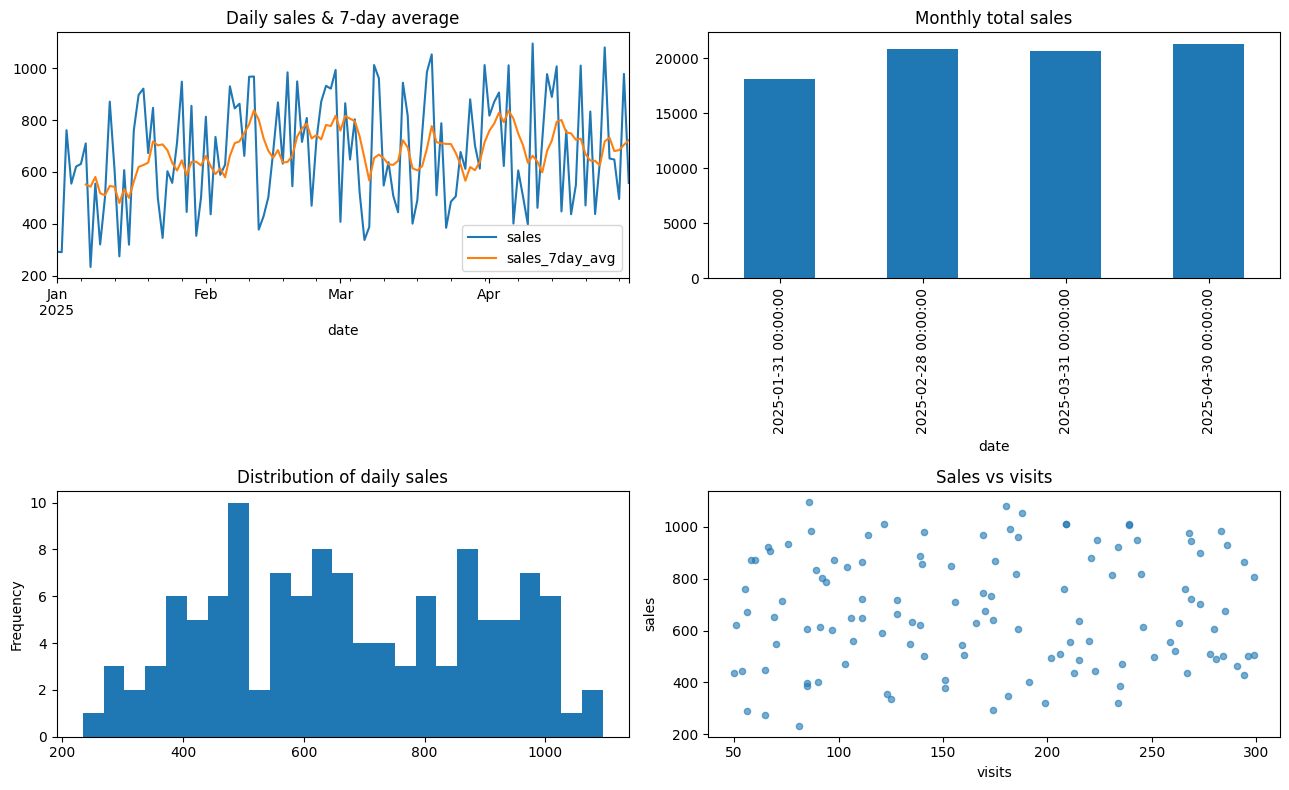

In [83]:
# --- plotting ---
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(13, 8))

tsi[['sales', 'sales_7day_avg']].plot(ax=axes[0, 0], title='Daily sales & 7-day average')
tsi['sales'].resample('ME').sum().plot(kind='bar', ax=axes[0, 1], title='Monthly total sales')
tsi['sales'].plot(kind='hist', bins=25, ax=axes[1, 0], title='Distribution of daily sales')
tsi.plot(kind='scatter', x='visits', y='sales', alpha=0.6, ax=axes[1, 1],
         title='Sales vs visits')

plt.tight_layout()
plt.show()

### File I/O

In Colab, files you write land in the temporary `/content` folder — visible in the
**Files** panel on the left. They disappear when the runtime restarts, so download
anything you need to keep.

Common readers: `read_csv`, `read_excel`, `read_json`, `read_html`, `read_parquet`,
`read_sql`. Each has a matching `to_*` writer.

In [84]:
# --- write, then read back ---
ts.to_csv('sales_data.csv', index=False)
print('written: sales_data.csv')

back = pd.read_csv('sales_data.csv', parse_dates=['date'])
print('read back ->', back.shape, '| date dtype:', back['date'].dtype)
display(back.head(3))

# other formats
ts.head(20).to_json('sample.json', orient='records', date_format='iso')
ts.to_excel('sales_data.xlsx', index=False)   # needs openpyxl, pre-installed in Colab
print('\nalso written: sample.json, sales_data.xlsx')

written: sales_data.csv
read back -> (120, 7) | date dtype: datetime64[ns]


,date,sales,visits,year,month,weekday,is_weekend
0,2025-01-01,293,174,2025,1,Wednesday,False
1,2025-01-02,291,56,2025,1,Thursday,False
2,2025-01-03,761,55,2025,1,Friday,False



also written: sample.json, sales_data.xlsx


In [85]:
# --- useful read_csv options (run this cell to see them in action) ---
demo = pd.read_csv('sales_data.csv',
                   usecols=['date', 'sales', 'visits'],  # only these columns
                   nrows=5,                              # only the first 5 rows
                   parse_dates=['date'])
display(demo)

# reading straight from a URL works too, e.g.:
# url = 'https://raw.githubusercontent.com/mwaskom/seaborn-data/master/titanic.csv'
# titanic = pd.read_csv(url)

,date,sales,visits
0,2025-01-01,293,174
1,2025-01-02,291,56
2,2025-01-03,761,55
3,2025-01-04,555,259
4,2025-01-05,621,51


**Uploading your own file in Colab** — run the cell below and pick a file from your
computer. (Skip it if you have nothing to upload; it will simply wait for a selection.)

In [86]:
# from google.colab import files
# uploaded = files.upload()               # opens a file picker
# my_df = pd.read_csv(next(iter(uploaded)))
# my_df.head()

# To download a file you created:
# files.download('sales_data.csv')

# To mount Google Drive:
# from google.colab import drive
# drive.mount('/content/drive')
# pd.read_csv('/content/drive/MyDrive/your_folder/your_file.csv')
print('Uncomment the lines you need.')

Uncomment the lines you need.


### Tasks — Lab 12

12.2


date
2025-01-31    18077
2025-02-28    20835
2025-03-31    20690
2025-04-30    21291
Freq: ME, Name: sales, dtype: int64

12.3 -> 2025-04-10 00:00:00


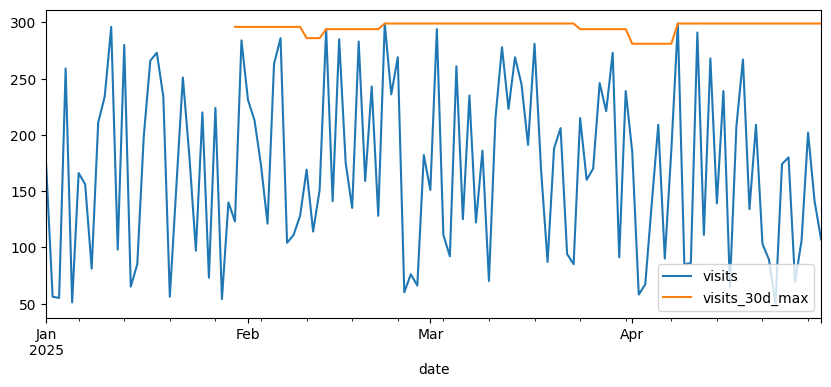

In [87]:
# TASK 12.1  Add a column `quarter` to `ts` using the .dt accessor.
ts['quarter'] = ts['date'].dt.quarter

# TASK 12.2  Total sales per month, as a Series (use resample on tsi).
q2 = tsi['sales'].resample('ME').sum()

# TASK 12.3  The date on which sales were highest.
q3 = tsi['sales'].idxmax()

# TASK 12.4  A 30-day rolling maximum of visits; plot it against daily visits.
tsi['visits_30d_max'] = tsi['visits'].rolling(30).max()
tsi[['visits', 'visits_30d_max']].plot(figsize=(10, 4))

print('12.2'); display(q2)
print('12.3 ->', q3)

<details>
<summary><b>Solutions — Lab 12</b></summary>

```python
ts['quarter'] = ts['date'].dt.quarter
q2 = tsi['sales'].resample('ME').sum()
q3 = tsi['sales'].idxmax()
tsi['visits_30d_max'] = tsi['visits'].rolling(30).max()
tsi[['visits', 'visits_30d_max']].plot(figsize=(10, 4))
```
</details>

---

# Lab 13 — Mini Project: End-to-End Analysis

### Aim
To apply the whole toolkit to one messy dataset and report findings.

### Scenario
You are given one year of transaction records from a small electronics retailer with
three branches. The data has missing values, inconsistent text and wrong dtypes —
as real data always does.

### Required deliverables
Complete the eight steps below. For each, write the code **and** a one-line conclusion
in the markdown cell at the end.

In [88]:
# --- generate the raw dataset (run this cell as-is) ---
rng = np.random.default_rng(2025)
n = 500

shop = pd.DataFrame({
    'txn_id'  : np.arange(1001, 1001 + n),
    'date'    : rng.choice(pd.date_range('2025-01-01', '2025-12-31'), n).astype(str),
    'branch'  : rng.choice(['bishkek', 'OSH', 'Karakol ', 'Bishkek'], n),
    'category': rng.choice(['Laptop', 'Phone', 'Accessory', 'Tablet'], n,
                           p=[0.25, 0.35, 0.30, 0.10]),
    'units'   : rng.integers(1, 6, n),
    'price'   : rng.choice([48000, 32000, 1500, 21000, 850, 15000], n).astype(float),
    'payment' : rng.choice(['cash', 'card', 'transfer', None], n, p=[.4, .4, .15, .05]),
})

# inject some mess
shop.loc[rng.choice(n, 30, replace=False), 'price'] = np.nan
shop.loc[rng.choice(n, 15, replace=False), 'units'] = np.nan
shop = pd.concat([shop, shop.sample(10, random_state=1)], ignore_index=True)  # duplicates

print('raw shape:', shop.shape)
shop.head()

raw shape: (510, 7)


,txn_id,date,branch,category,units,price,payment
0,1001,2025-06-13T00:00:00.000000000,OSH,Laptop,3.0,850.0,card
1,1002,2025-12-29T00:00:00.000000000,OSH,Accessory,5.0,850.0,transfer
2,1003,2025-12-29T00:00:00.000000000,OSH,Tablet,1.0,21000.0,card
3,1004,2025-05-20T00:00:00.000000000,Bishkek,Phone,3.0,21000.0,card
4,1005,2025-12-15T00:00:00.000000000,bishkek,Accessory,3.0,32000.0,cash


In [89]:
# STEP 1  Inspect: shape, dtypes, missing counts, duplicate count.
print('shape      :', shop.shape)
print('\ndtypes:\n', shop.dtypes, sep='')
print('\nmissing values:\n', shop.isna().sum(), sep='')
print('\nduplicate rows:', shop.duplicated().sum())

shape      : (510, 7)

dtypes:
txn_id        int64
date         object
branch       object
category     object
units       float64
price       float64
payment      object
dtype: object

missing values:
txn_id       0
date         0
branch       0
category     0
units       16
price       30
payment     33
dtype: int64

duplicate rows: 10


In [90]:
# STEP 2  Clean:
#   - drop duplicate rows
#   - parse `date` as datetime
#   - normalise `branch` (strip whitespace, title case)
#   - fill missing `price` with the median price OF ITS CATEGORY (hint: groupby + transform)
#   - fill missing `units` with 1
#   - fill missing `payment` with 'unknown'
n_raw = len(shop)
shop = shop.drop_duplicates().copy()
dups_removed = n_raw - len(shop)
missing_filled = int(shop[['price', 'units', 'payment']].isna().sum().sum())

shop['date'] = pd.to_datetime(shop['date'])
shop['branch'] = shop['branch'].str.strip().str.title()
shop['price'] = shop['price'].fillna(shop.groupby('category')['price'].transform('median'))
shop['units'] = shop['units'].fillna(1).astype(int)
shop['payment'] = shop['payment'].fillna('unknown')

print('rows after cleaning:', shop.shape, '| duplicates removed:', dups_removed, '| missing filled:', missing_filled)
print(shop.isna().sum().sum(), 'missing values left;', shop['branch'].unique())

rows after cleaning: (500, 7) | duplicates removed: 10 | missing filled: 78
0 missing values left; ['Osh' 'Bishkek' 'Karakol']


In [91]:
# STEP 3  Feature engineering:
#   - `revenue` = units * price
#   - `month` (period or month number) and `weekday` name from `date`
#   - `basket_size` band using pd.cut on revenue: small / medium / large
shop['revenue'] = shop['units'] * shop['price']
shop['month'] = shop['date'].dt.month
shop['weekday'] = shop['date'].dt.day_name()
shop['basket_size'] = pd.cut(shop['revenue'], bins=[0, 10_000, 50_000, np.inf],
                             labels=['small', 'medium', 'large'])
display(shop.head())
print(shop['basket_size'].value_counts())

,txn_id,date,branch,category,units,price,payment,revenue,month,weekday,basket_size
0,1001,2025-06-13,Osh,Laptop,3,850.0,card,2550.0,6,Friday,small
1,1002,2025-12-29,Osh,Accessory,5,850.0,transfer,4250.0,12,Monday,small
2,1003,2025-12-29,Osh,Tablet,1,21000.0,card,21000.0,12,Monday,medium
3,1004,2025-05-20,Bishkek,Phone,3,21000.0,card,63000.0,5,Tuesday,large
4,1005,2025-12-15,Bishkek,Accessory,3,32000.0,cash,96000.0,12,Monday,large


basket_size
large     216
small     168
medium    116
Name: count, dtype: int64


In [92]:
# STEP 4  Which branch earned the most total revenue? Which has the highest average
#         revenue per transaction? Are they the same branch?
by_branch = shop.groupby('branch')['revenue'].agg(total='sum', average='mean').round(0)
display(by_branch)
print('Highest total revenue     :', by_branch['total'].idxmax())
print('Highest avg per transaction:', by_branch['average'].idxmax())
print('Same branch?', by_branch['total'].idxmax() == by_branch['average'].idxmax())

,total,average
branch,,
Bishkek,1.478e+07,57976.0
Karakol,5.884e+06,49863.0
Osh,8.135e+06,64052.0


Highest total revenue     : Bishkek
Highest avg per transaction: Osh
Same branch? False


In [93]:
# STEP 5  Build a pivot table of total revenue with rows=month, columns=category.
pivot = pd.pivot_table(shop, values='revenue', index='month', columns='category',
                       aggfunc='sum', fill_value=0)
display(pivot)

category,Accessory,Laptop,Phone,Tablet
month,,,,
1,5.198e+05,7.066e+05,8.332e+05,189850.0
2,5.614e+05,4.514e+05,1.635e+06,63000.0
3,5.654e+05,2.998e+05,5.500e+05,368000.0
4,9.964e+05,6.272e+05,5.974e+05,54500.0
5,6.165e+05,8.576e+05,2.076e+06,47550.0
6,6.030e+05,1.322e+06,9.300e+05,117000.0
7,7.058e+05,5.185e+05,5.972e+05,148500.0
8,1.044e+06,6.348e+05,4.630e+05,283500.0
9,2.008e+05,9.905e+05,6.448e+05,126000.0


In [94]:
# STEP 6  For each branch, find its single best-selling category by units sold.
units_bc = shop.groupby(['branch', 'category'])['units'].sum()
best_cat = units_bc.groupby('branch').idxmax().map(lambda t: t[1])
display(units_bc.groupby('branch').max().to_frame('units').assign(best_category=best_cat))

,units,best_category
branch,,
Bishkek,271,Phone
Karakol,115,Phone
Osh,164,Phone


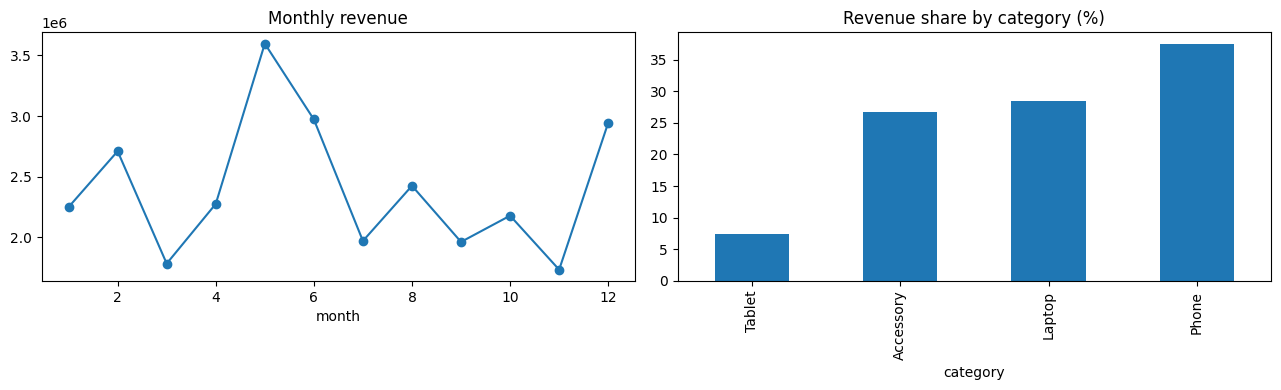

In [95]:
# STEP 7  Plot: (a) monthly revenue as a line, (b) revenue share by category as a bar chart.
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
shop.groupby('month')['revenue'].sum().plot(ax=axes[0], marker='o', title='Monthly revenue')
(shop.groupby('category')['revenue'].sum() / shop['revenue'].sum() * 100).sort_values().plot(
    kind='bar', ax=axes[1], title='Revenue share by category (%)')
plt.tight_layout()
plt.show()

In [96]:
# STEP 8  Export the cleaned dataset to 'shop_clean.csv' and the month x category
#         pivot to 'summary.xlsx'.
shop.to_csv('shop_clean.csv', index=False)
pivot.to_excel('summary.xlsx')
print('saved shop_clean.csv and summary.xlsx')

saved shop_clean.csv and summary.xlsx


### Mini-project report

**Dataset:** 500 rows × 11 columns after cleaning (10 duplicates removed,
78 missing values filled).

**Finding 1 — Branch performance:** Bishkek earned the most total revenue (about 14.8 M, 51% of the 28.8 M total) because it has the most transactions (255). Osh has the highest average revenue per transaction (about 64,052 vs 57,976 in Bishkek), so they are not the same branch. Karakol is the smallest on both measures.

**Finding 2 — Category mix:** Phones lead with 37.4% of revenue and 550 units, followed by laptops (28.4%) and accessories (26.8%). Tablets are only 7.4%. Phone is the best-selling category by units in all three branches.

**Finding 3 — Seasonality:** Revenue peaks in May (about 3.6 M) and is also strong in June and December (about 2.9 M each). The weakest months are November (1.7 M), March (1.8 M) and September (2.0 M). Phone sales drive the May and February peaks.

**Finding 4 — Payment behaviour:** Card (43%) and cash (36%) make up most transactions; transfer is 15% and 6.6% have no recorded method. Transfer has the lowest average ticket (about 49,900), while cash and card are similar (about 58,000).

**Conclusion:** Bishkek and phones carry the business. To grow, the retailer could stock more phones before the May and December peaks, push Osh's higher-value basket model to other branches, and record the payment method for every sale. Note that the data is simulated and prices do not depend on category, so these patterns should be checked on real data.

---

# Appendix A — Quick Reference

### NumPy

```python
np.array(lst)            np.arange(a, b, s)      np.linspace(a, b, n)
np.zeros(sh)             np.ones(sh)             np.full(sh, v)      np.eye(n)
rng = np.random.default_rng(seed)
rng.random(sh)           rng.integers(lo, hi, sh)  rng.normal(mu, sd, sh)

a.shape  a.ndim  a.size  a.dtype  a.nbytes
a.reshape(r, c)   a.ravel()   a.T   a.astype(t)   a.copy()
a[i, j]  a[r0:r1, c0:c1]  a[mask]  a[[i1, i2]]

a.sum(axis=)  a.mean()  a.std()  a.min()  a.max()  a.cumsum()
a.argmin()  a.argmax()  a.argsort()  np.sort(a)  np.unique(a)
np.where(cond, x, y)   np.clip(a, lo, hi)   np.concatenate([a, b])
a @ b   np.linalg.inv(A)   np.linalg.det(A)   np.linalg.solve(A, b)
```

### pandas

```python
pd.Series(data, index=)          pd.DataFrame(dict_of_lists)
pd.read_csv(path)               df.to_csv(path, index=False)

df.shape  df.head()  df.info()  df.describe()  df.dtypes  df.columns
df.isna().sum()   df['c'].value_counts()   df['c'].unique()

df['c']            df[['c1','c2']]
df.loc[rows, cols]            # by label, end INCLUSIVE
df.iloc[rows, cols]           # by position, end exclusive
df[(df.a > 1) & (df.b == 'x')]        df.query('a > 1')
df.sort_values('c', ascending=False)  df.nlargest(n, 'c')

df.dropna(subset=)  df.fillna(v)  df.drop_duplicates()  df.rename(columns=)
pd.to_numeric(s, errors='coerce')     pd.to_datetime(s)
df['c'].str.strip().str.lower()       df['c'].astype(t)

df.groupby('k')['v'].sum()
df.groupby('k').agg(new=('v', 'mean'))
df.groupby('k')['v'].transform('sum')
pd.pivot_table(df, values=, index=, columns=, aggfunc=)
pd.crosstab(df.a, df.b)               pd.cut(s, bins=, labels=)

pd.merge(l, r, on='k', how='left')    pd.concat([a, b], ignore_index=True)
df.set_index('c')   df.reset_index()  df.apply(f)  df['c'].map(f)
s.dt.year  s.dt.month  s.dt.day_name()   df.resample('ME').sum()
df.plot()   df.plot(kind='bar'|'hist'|'scatter'|'box')
```

---

# Appendix B — Common Errors and Their Cause

| Message | Usual cause | Fix |
|---|---|---|
| `ValueError: operands could not be broadcast together` | incompatible shapes | check `.shape`; add an axis with `[:, None]` |
| `IndexError: index 5 is out of bounds for axis 0 with size 5` | off-by-one | valid indices are `0 .. size-1` |
| `KeyError: 'col'` | column name typo or stray whitespace | `df.columns.tolist()`; `df.columns.str.strip()` |
| `ValueError: The truth value of a Series is ambiguous` | used `and` / `or` on a Series | use `&` / `\|` with parentheses |
| `SettingWithCopyWarning` | chained assignment | one `df.loc[mask, 'col'] = v` |
| `TypeError: unsupported operand type(s) for +: 'int' and 'str'` | numeric column stored as text | `pd.to_numeric(..., errors='coerce')` |
| `ValueError: cannot reshape array of size 12 into shape (5,3)` | sizes must match | product of new shape must equal `size` |
| `NameError: name 'np' is not defined` | ran a cell out of order | `Runtime → Restart and run all` |

---

# Appendix C — Marking Scheme

| Component | Marks |
|---|---:|
| Labs 1–5 tasks (NumPy) | 20 |
| Labs 6–12 tasks (pandas) | 30 |
| Viva answers | 10 |
| Mini project — cleaning & correctness | 20 |
| Mini project — analysis & plots | 10 |
| Report, neatness, reproducibility | 10 |
| **Total** | **100** |

---

*End of lab manual.*